# HỆ TRUY HỒI VĂN BẢN TIẾNG VIỆT — DOC2VEC HYBRID V6.4

Notebook rút gọn từ phiên bản thực nghiệm.

Pipeline cuối:

**Dataset 3.000 bài báo → Preprocessing V5 → Doc2Vec → Candidate pool (Doc2Vec Top-50 ∪ BM25 Top-50) → Category Coverage → Context-aware Document Match → Hybrid Reranking (Doc2Vec cosine là lõi) → Top-10 → Giao diện Search**

V6.4 so với V6.3: BM25 **chỉ dùng để mở rộng candidate pool**, không cộng vào điểm xếp hạng. Bảng ablation (có/không từng thành phần) ở BƯỚC 7B.

Chỉ giữ các thành phần cần thiết cho bài toán cuối.

Phần bổ sung (BƯỚC 8 → 12):
- **BƯỚC 8** — Hỗ trợ query không dấu / sai chính tả (bigram LM âm tiết + Viterbi) và đánh giá.
- **BƯỚC 9** — Phương pháp so sánh: TF-IDF, PhoBERT; hàm truy hồi chung theo độ đo.
- **BƯỚC 10** — Lựa chọn độ đo cosine / Euclidean / dot product: giải thích, trực quan hoá, đánh giá.
- **BƯỚC 11** — Bảng/hình cho tiểu luận: dataset, độ dài, thời gian train, t-SNE/UMAP, so sánh phương pháp.
- **BƯỚC 12** — Giao diện web Gradio (`share=True` trên Colab): dropdown phương pháp, latency, giải thích điểm.

## BƯỚC 1 — Cài thư viện, cấu hình đường dẫn và đọc dataset

Dataset sử dụng: `vietnamese_news_3000.csv`.

Mọi đường dẫn nằm trong khối **CẤU HÌNH** của cell dưới (`PROJECT_DIR`, `DATASET_PATH`, `STOPWORDS_PATH`, `CACHE_DIR`).
Trên Colab, `PROJECT_DIR` mặc định là `/content/drive/MyDrive/Colab_Notebooks`; có thể đổi trực tiếp hoặc đặt biến môi trường `IRS_PROJECT_DIR`.
Cell sẽ báo lỗi ngay nếu thiếu file dataset hoặc file stopwords.

`df_docs` (sau preprocessing) và model Doc2Vec được **cache** trong `CACHE_DIR`. Lần chạy sau chỉ load lại, không preprocessing/train lại.
Đặt `FORCE_REBUILD = True` nếu muốn bỏ cache.

Các cột cần có:
- `doc_id`
- `title`
- `category`
- `content`

In [3]:
# ============================================================
# BƯỚC 1 — SETUP + CẤU HÌNH + LOAD DATASET
# ============================================================

!pip -q install underthesea gensim ipywidgets rank_bm25

import os
import sys
import re
import html
import json
import hashlib
import time
import numpy as np
import pandas as pd

from pathlib import Path
from collections import Counter, defaultdict
from underthesea import word_tokenize
from gensim.models.doc2vec import Doc2Vec, TaggedDocument

IN_COLAB = "google.colab" in sys.modules

if IN_COLAB:
    from google.colab import drive
    drive.mount("/content/drive")

# ============================================================
# CẤU HÌNH
# Đổi PROJECT_DIR nếu dữ liệu nằm ở thư mục khác,
# hoặc đặt biến môi trường IRS_PROJECT_DIR.
# ============================================================
DEFAULT_PROJECT_DIR = (
    "/content/drive/MyDrive/Colab_Notebooks/Ki_2/IRS"
    if IN_COLAB
    else "."
)

PROJECT_DIR = Path(
    os.environ.get("IRS_PROJECT_DIR", DEFAULT_PROJECT_DIR)
)

DATASET_PATH = PROJECT_DIR / "vietnamese_news_3000.csv"
# Stopword removal chạy SAU word segmentation (token dạng "ai_ai"),
# nên dùng bản "-dash" (từ ghép nối bằng "_"):
# https://github.com/stopwords/vietnamese-stopwords
STOPWORDS_PATH = PROJECT_DIR / "vietnamese-stopwords-dash.txt"
CACHE_DIR = PROJECT_DIR / "irs_cache_v5"

# True: bỏ qua cache, preprocessing + train lại từ đầu
FORCE_REBUILD = False

for required_path in [DATASET_PATH, STOPWORDS_PATH]:
    if not required_path.is_file():
        raise FileNotFoundError(
            f"Không tìm thấy file: {required_path}\n"
            f"Kiểm tra lại PROJECT_DIR = {PROJECT_DIR}"
        )

CACHE_DIR.mkdir(parents=True, exist_ok=True)

print("PROJECT_DIR :", PROJECT_DIR)
print("DATASET_PATH:", DATASET_PATH)
print("CACHE_DIR   :", CACHE_DIR)

df = pd.read_csv(DATASET_PATH)

required_columns = {"doc_id", "title", "category", "content"}
missing_columns = required_columns - set(df.columns)

if missing_columns:
    raise KeyError(f"Dataset thiếu các cột: {sorted(missing_columns)}")

print("Dataset shape:", df.shape)
print("\nPhân bố category:")
print(df["category"].value_counts())


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
PROJECT_DIR : /content/drive/MyDrive/Colab_Notebooks/Ki_2/IRS
DATASET_PATH: /content/drive/MyDrive/Colab_Notebooks/Ki_2/IRS/vietnamese_news_3000.csv
CACHE_DIR   : /content/drive/MyDrive/Colab_Notebooks/Ki_2/IRS/irs_cache_v5
Dataset shape: (3000, 7)

Phân bố category:
category
Chinh tri Xa hoi    300
Doi song            300
Khoa hoc            300
Kinh doanh          300
Phap luat           300
Suc khoe            300
The gioi            300
The thao            300
Van hoa             300
Vi tinh             300
Name: count, dtype: int64


## BƯỚC 2 — Chuẩn bị dữ liệu

Giữ nguyên dữ liệu gốc trong `df`, tạo `df_docs` phục vụ mô hình.

Chỉ loại document không có nội dung.

Nếu BƯỚC 3 tìm thấy cache hợp lệ, `df_docs` sẽ được thay bằng bản đã preprocessing trong cache.

In [4]:
# ============================================================
# BƯỚC 2 — PREPARE DOCUMENTS
# ============================================================
# Vậy column `content_segments` trong csv là cái gì? để làm gì? Tại sao nó ý chang column `content` vậy?

df_docs = df.copy()

df_docs["doc_id"] = df_docs["doc_id"].astype(str)

df_docs["text_raw"] = (
    df_docs["content"]
    .fillna("")
    .astype(str)
    .str.strip()
)

df_docs["title"] = (
    df_docs["title"]
    .fillna("")
    .astype(str)
    .str.strip()
)

df_docs = (
    df_docs[df_docs["text_raw"] != ""]
    .drop_duplicates(subset=["doc_id"])
    .reset_index(drop=True)
)

print("Số document dùng cho retrieval:", len(df_docs))
print("Số category:", df_docs["category"].nunique())

display(
    df_docs[
        ["doc_id", "title", "category", "text_raw"]
    ].head(3)
)

Số document dùng cho retrieval: 3000
Số category: 10


,doc_id,title,category,text_raw
0,DOC_0001,Đề nghị Chính phủ bổ sung 100 tỷ đồng chống hạ...,Chinh tri Xa hoi,Đề nghị Chính phủ bổ sung 100 tỷ đồng chống hạ...
1,DOC_0002,Thêm một chuyến xe buýt TP.HCM - Phnom Penh Xe...,Chinh tri Xa hoi,Thêm một chuyến xe buýt TP.HCM - Phnom Penh Xe...
2,DOC_0003,Xác định rõ hơn định hướng của VN - Tiến trình...,Chinh tri Xa hoi,Xác định rõ hơn định hướng của VN - Tiến trình...


## BƯỚC 3 — Preprocessing V5

Pipeline đã chốt trong quá trình thực nghiệm:

1. Loại HTML/XML và URL.
2. Giữ hoa/thường trước Word Segmentation.
3. Tách từ tiếng Việt bằng Underthesea.
4. Lowercase sau segmentation.
5. Loại token số/ngày/mã nhiễu.
6. Loại token không có chữ, token một ký tự và stopwords.

Stopword removal được áp dụng **sau** word segmentation, khi token đã có dạng `ai_ai`, `bởi_vì`. Vì vậy notebook dùng file `vietnamese-stopwords-dash.txt` (từ ghép nối bằng `_`) của repo [stopwords/vietnamese-stopwords](https://github.com/stopwords/vietnamese-stopwords). Bản có dấu cách (`vietnamese-stopwords.txt`) sẽ không khớp được các stopword nhiều âm tiết.

Cùng một hàm preprocessing được dùng cho **document và query**.

**Cache:** kết quả preprocessing của corpus được lưu vào `CACHE_DIR/df_docs_v5.pkl`. Cache chỉ được dùng khi *fingerprint* (MD5 của dataset + file stopwords + phiên bản preprocessing) khớp; nếu dataset hoặc stopwords thay đổi, cell tự preprocessing lại.

In [5]:
with open(STOPWORDS_PATH, 'r', encoding='utf-8') as f:
  stopword_list = [line.strip() for line in f]

print(stopword_list[:5])


['a_lô', 'a_ha', 'ai', 'ai_ai', 'ai_nấy']


In [6]:
# ============================================================
# BƯỚC 3 — PREPROCESSING V5
# ============================================================
stopwords_v4 = stopword_list


def normalize_text_v5(text):
    if not isinstance(text, str):
        return ""

    text = html.unescape(text)
    text = re.sub(r"<[^>]+>", " ", text)
    text = re.sub(r"https?://\S+|www\.\S+", " ", text)
    text = re.sub(r"\s+", " ", text).strip()

    return text


def clean_token_v5(token):
    token = str(token).strip()

    token = re.sub(r"^[^\wÀ-ỹ]+", "", token)
    token = token.strip("_")
    token = re.sub(r"[^\wÀ-ỹ]+$", "", token)
    token = token.strip("_")

    return token


def is_noise_token_v5(token):
    token = str(token).strip().lower()

    if not token:
        return True

    # số thuần
    if re.fullmatch(r"\d+", token):
        return True

    # số có dấu phân cách: 145.000, 12,5...
    if re.fullmatch(r"\d+(?:[.,]\d+)+", token):
        return True

    # ngày tháng: 13-2, 25/6/2024...
    if re.fullmatch(
        r"\d{1,4}[-/]\d{1,2}(?:[-/]\d{1,4})?",
        token
    ):
        return True

    # mã chữ-số có - hoặc /
    if (
        re.search(r"\d", token)
        and re.search(r"[a-zA-ZÀ-ỹ]", token)
        and re.search(r"[-/]", token)
    ):
        return True

    # dạng giờ bị vỡ như g30
    if re.fullmatch(r"[a-zA-ZÀ-ỹ]\d+", token):
        return True

    return False


def segment_for_doc2vec_v5(text, stopwords=None):
    text = normalize_text_v5(text)

    if not text:
        return []

    # Word Segmentation trước lowercase
    segmented = word_tokenize(text, format="text")
    tokens = segmented.split()

    # lowercase sau segmentation
    tokens = [token.lower() for token in tokens]

    # cleanup
    tokens = [clean_token_v5(token) for token in tokens]
    tokens = [token for token in tokens if token]

    # loại noise
    tokens = [
        token for token in tokens
        if not is_noise_token_v5(token)
    ]

    # phải có ít nhất một chữ
    tokens = [
        token for token in tokens
        if re.search(r"[a-zA-ZÀ-ỹ]", token)
    ]

    # bỏ token đơn ký tự
    tokens = [
        token for token in tokens
        if len(token) > 1
    ]

    # stopwords
    if stopwords is not None:
        stopword_set = set(stopwords)
        tokens = [
            token for token in tokens
            if token not in stopword_set
        ]

    return tokens


# ============================================================
# CACHE HELPERS
# ============================================================
PREPROCESS_VERSION = "v5"


def file_md5(path, chunk_size=1 << 20):
    digest = hashlib.md5()

    with open(path, "rb") as f:
        for chunk in iter(lambda: f.read(chunk_size), b""):
            digest.update(chunk)

    return digest.hexdigest()


def cache_is_valid(cache_path, meta_path, fingerprint):
    if FORCE_REBUILD:
        return False

    if not (cache_path.is_file() and meta_path.is_file()):
        return False

    try:
        meta = json.loads(meta_path.read_text(encoding="utf-8"))
    except (OSError, ValueError):
        return False

    return meta.get("fingerprint") == fingerprint


def write_cache_meta(meta_path, fingerprint, **extra):
    meta_path.write_text(
        json.dumps({"fingerprint": fingerprint, **extra}),
        encoding="utf-8"
    )


DATA_FINGERPRINT = hashlib.md5(
    (
        file_md5(DATASET_PATH)
        + file_md5(STOPWORDS_PATH)
        + PREPROCESS_VERSION
    ).encode("utf-8")
).hexdigest()

DF_DOCS_CACHE = CACHE_DIR / "df_docs_v5.pkl"
DF_DOCS_META = CACHE_DIR / "df_docs_v5.meta.json"


# ============================================================
# PREPROCESS CORPUS (chỉ chạy khi chưa có cache hợp lệ)
# ============================================================
df_docs_from_cache = False

if cache_is_valid(DF_DOCS_CACHE, DF_DOCS_META, DATA_FINGERPRINT):
    try:
        df_docs = pd.read_pickle(DF_DOCS_CACHE)
        df_docs_from_cache = True
        print("Đã load df_docs từ cache:", DF_DOCS_CACHE)
    except Exception as e:
        print("Không đọc được cache, preprocessing lại:", e)

if not df_docs_from_cache:
    print("Đang preprocessing 3.000 documents...")
    preprocess_start = time.perf_counter()

    df_docs["tokens_v5"] = df_docs["text_raw"].apply(
        lambda text: segment_for_doc2vec_v5(
            text,
            stopwords=stopwords_v4
        )
    )

    # Giữ cả LIST (có thứ tự) và SET (tra cứu nhanh)
    df_docs["token_set_v5"] = df_docs["tokens_v5"].apply(set)

    df_docs["title_tokens_list_v5"] = df_docs["title"].apply(
        lambda text: segment_for_doc2vec_v5(
            text,
            stopwords=stopwords_v4
        )
    )

    df_docs["title_token_set_v5"] = df_docs["title_tokens_list_v5"].apply(set)

    df_docs.to_pickle(DF_DOCS_CACHE)
    write_cache_meta(
        DF_DOCS_META,
        DATA_FINGERPRINT,
        seconds=time.perf_counter() - preprocess_start  # dùng cho Bảng 11.2
    )

    print("Preprocessing hoàn tất. Đã lưu cache:", DF_DOCS_CACHE)

empty_count = (df_docs["tokens_v5"].str.len() == 0).sum()

print("Document rỗng sau preprocessing:", empty_count)

display(
    df_docs[
        ["doc_id", "title", "tokens_v5"]
    ].head(3)
)


Đã load df_docs từ cache: /content/drive/MyDrive/Colab_Notebooks/Ki_2/IRS/irs_cache_v5/df_docs_v5.pkl
Document rỗng sau preprocessing: 0


,doc_id,title,tokens_v5
0,DOC_0001,Đề nghị Chính phủ bổ sung 100 tỷ đồng chống hạ...,"[đề_nghị, chính_phủ, bổ_sung, tỷ, đồng, chống,..."
1,DOC_0002,Thêm một chuyến xe buýt TP.HCM - Phnom Penh Xe...,"[chuyến, xe_buýt, tp.hcm, phnom_penh, xe, chỗ,..."
2,DOC_0003,Xác định rõ hơn định hướng của VN - Tiến trình...,"[xác_định, định_hướng, vn, tiến_trình, phát_tr..."


## BƯỚC 4 — Xây `TaggedDocument` và huấn luyện Doc2Vec V5

Cấu hình cuối:
- `vector_size = 100`
- `window = 5`
- `min_count = 2`
- `epochs = 40`
- `dm = 0` → PV-DBOW
- `dbow_words = 1`
- `negative = 5`
- `seed = 42`

**Cache:** model được lưu ở `CACHE_DIR/doc2vec_v5.model` và chỉ train khi chưa có model hợp lệ (fingerprint = dữ liệu + tham số Doc2Vec). Ngoài việc tiết kiệm thời gian, load cùng một model còn giúp kết quả demo ổn định giữa các lần mở notebook, vì train với `workers = 4` không cho kết quả giống hệt nhau dù cố định `seed`.

In [7]:
# ============================================================
# BƯỚC 4 — TRAIN DOC2VEC V5 (hoặc load từ cache)
# ============================================================

DOC2VEC_PARAMS = dict(
    vector_size=100,
    window=5,
    min_count=2,
    workers=4,
    epochs=40,
    dm=0,              # PV-DBOW
    dbow_words=1,
    negative=5,
    seed=42
)

MODEL_FINGERPRINT = hashlib.md5(
    (
        DATA_FINGERPRINT
        + json.dumps(DOC2VEC_PARAMS, sort_keys=True)
    ).encode("utf-8")
).hexdigest()

MODEL_CACHE = CACHE_DIR / "doc2vec_v5.model"
MODEL_META = CACHE_DIR / "doc2vec_v5.meta.json"

model_from_cache = False

if cache_is_valid(MODEL_CACHE, MODEL_META, MODEL_FINGERPRINT):
    try:
        model_v5 = Doc2Vec.load(str(MODEL_CACHE))
        model_from_cache = True
        print("Đã load Doc2Vec từ cache:", MODEL_CACHE)
    except Exception as e:
        print("Không đọc được model cache, train lại:", e)

if not model_from_cache:
    tagged_documents_v5 = [
        TaggedDocument(
            words=row["tokens_v5"],
            tags=[row["doc_id"]]
        )
        for _, row in df_docs.iterrows()
        if len(row["tokens_v5"]) > 0
    ]

    print("TaggedDocument:", len(tagged_documents_v5))

    train_start = time.perf_counter()
    model_v5 = Doc2Vec(**DOC2VEC_PARAMS)

    model_v5.build_vocab(tagged_documents_v5)

    print("Corpus count:", model_v5.corpus_count)

    model_v5.train(
        tagged_documents_v5,
        total_examples=model_v5.corpus_count,
        epochs=model_v5.epochs
    )

    model_v5.save(str(MODEL_CACHE))
    write_cache_meta(
        MODEL_META,
        MODEL_FINGERPRINT,
        seconds=time.perf_counter() - train_start  # dùng cho Bảng 11.2
    )

    print("TRAIN V5 HOÀN TẤT. Đã lưu model:", MODEL_CACHE)

print("Vocabulary size:", len(model_v5.wv))
print("Document vectors:", len(model_v5.dv))


Đã load Doc2Vec từ cache: /content/drive/MyDrive/Colab_Notebooks/Ki_2/IRS/irs_cache_v5/doc2vec_v5.model
Vocabulary size: 21187
Document vectors: 3000


## BƯỚC 5 — Tạo Category Coverage Index

Mục đích: với mỗi category, đếm số document chứa từng token.

Không dùng Top-30 Strong Keyword nữa vì thử nghiệm cho thấy exact keyword matching quá hẹp.  
V6.1 dùng trực tiếp **Document Frequency của query token trong từng category**.

In [8]:
# ============================================================
# BƯỚC 5 — CATEGORY TOKEN COVERAGE INDEX
# ============================================================

CATEGORY_COL = "category"

category_sizes = (
    df_docs
    .groupby(CATEGORY_COL)
    .size()
    .to_dict()
)

category_token_df = defaultdict(Counter)

for _, row in df_docs.iterrows():
    category_token_df[row[CATEGORY_COL]].update(
        row["token_set_v5"]
    )

print("Category Coverage Index hoàn tất.")

for category, size in category_sizes.items():
    print(f"{category:<22}: {size} documents")


# ============================================================
# GLOBAL DOCUMENT FREQUENCY
# Dùng cho relevance gate ở V6.3
# ============================================================

global_token_df = Counter()

for token_set in df_docs["token_set_v5"]:
    global_token_df.update(token_set)

TOTAL_DOCS = len(df_docs)

print("\nGlobal DF index hoàn tất.")
print("TOTAL_DOCS:", TOTAL_DOCS)


def compute_query_category_coverage_v6(query_text):
    query_tokens = segment_for_doc2vec_v5(
        query_text,
        stopwords=stopwords_v4
    )

    # bỏ duplicate nhưng giữ thứ tự
    query_tokens = list(dict.fromkeys(query_tokens))

    rows = []

    for category, category_size in category_sizes.items():
        coverage_score = 0.0
        matched_token_count = 0

        for token in query_tokens:
            doc_freq = category_token_df[category][token]

            if doc_freq > 0:
                matched_token_count += 1

            if category_size > 0:
                coverage_score += doc_freq / category_size

        rows.append({
            "category": category,
            "matched_token_count": matched_token_count,
            "coverage_score": coverage_score
        })

    df_category_score = (
        pd.DataFrame(rows)
        .sort_values(
            ["coverage_score", "matched_token_count"],
            ascending=[False, False]
        )
        .reset_index(drop=True)
    )

    return query_tokens, df_category_score

Category Coverage Index hoàn tất.
Chinh tri Xa hoi      : 300 documents
Doi song              : 300 documents
Khoa hoc              : 300 documents
Kinh doanh            : 300 documents
Phap luat             : 300 documents
Suc khoe              : 300 documents
The gioi              : 300 documents
The thao              : 300 documents
Van hoa               : 300 documents
Vi tinh               : 300 documents

Global DF index hoàn tất.
TOTAL_DOCS: 3000


## BƯỚC 6 — Retrieval cuối V6.4 (BM25 mở rộng candidate + context-aware + relevance gate)

V6.3/V6.4 khắc phục lỗi **“cùng category nhưng không thật sự liên quan nội dung”** bằng ba tín hiệu:

\[
HybridScore
= 0.65 \times Doc2Vec
+ 0.10 \times CategoryCoverage
+ 0.25 \times DocumentMatch
\]

Trong đó `DocumentMatch` không chỉ kiểm tra token đơn lẻ mà còn kiểm tra **bigram / cụm hai token liên tiếp**, giúp phân biệt các trường hợp như:

- `xây_dựng đội_hình`
- `chuẩn_bị thi_đấu`

với các văn bản chỉ vô tình có token chung như `xây_dựng`, `chuẩn_bị`.

Quy trình:
1. **Candidate pool = Doc2Vec Top-50 ∪ BM25 Top-50.**
   - BM25 (Okapi, thư viện `rank_bm25`, k1 = 1.5, b = 0.75) chỉ có nhiệm vụ đưa thêm vào pool những tài liệu khớp từ vựng mà Doc2Vec bỏ sót. Nếu chỉ lấy Top-50 của Doc2Vec, các tài liệu này không bao giờ được rerank.
   - **BM25 không cộng vào `hybrid_score`.** Với mọi candidate, kể cả candidate do BM25 đưa vào, `doc2vec_score` là cosine giữa vector query và vector tài liệu. Cosine Doc2Vec vẫn là thành phần lõi với trọng số 0.65.
   - Cột `candidate_source` cho biết candidate đến từ `Doc2Vec`, `BM25` hay cả hai.
2. Category Coverage bổ sung tín hiệu chủ đề.
3. Document Match đo **token overlap + phrase/bigram overlap** ở title và toàn văn.
4. Relevance gate, rerank và trả Top-10.

Tham khảo BM25: Robertson, S. & Zaragoza, H. (2009). *The Probabilistic Relevance Framework: BM25 and Beyond.* Foundations and Trends in IR 3(4), 333–389. DOI 10.1561/1500000019.
`rank_bm25.BM25Okapi` đặt sàn cho IDF âm (epsilon × IDF trung bình) theo tài liệu của thư viện: https://github.com/dorianbrown/rank_bm25

**Lưu ý về điểm số:** ba thành phần được min-max normalize *trong candidate pool của từng query* trước khi cộng trọng số. Vì vậy `hybrid_score` chỉ là **điểm tương đối dùng để xếp hạng** trong một query (tài liệu đứng đầu pool luôn gần 1). Nó **không** phải xác suất hay độ tin cậy, và không so sánh được giữa các query.
Để tham chiếu, kết quả hiển thị thêm `doc2vec_score`: cosine similarity gốc giữa vector query (`infer_vector`) và vector tài liệu, không bị chuẩn hoá theo query.

In [9]:
# ============================================================
# BƯỚC 6 — FINAL HYBRID RETRIEVAL V6.4
# Candidate : Doc2Vec Top-50 ∪ BM25 Top-50
# Rerank    : Doc2Vec cosine (lõi) + Category Coverage
#             + Context-aware Document Match + Relevance Gate
# BM25 CHỈ mở rộng candidate pool, KHÔNG cộng vào hybrid_score.
# ============================================================

from rank_bm25 import BM25Okapi

V64_DOC2VEC_WEIGHT = 0.65
V64_CATEGORY_WEIGHT = 0.10
V64_DOCUMENT_WEIGHT = 0.25

V64_CANDIDATE_POOL = 50   # Doc2Vec Top-N
V64_BM25_POOL = 50        # BM25 Top-N (chỉ mở rộng pool)
V64_TOP_K = 10

# ↓ Có chắc là phổ biến ???
# Token xuất hiện quá 20% corpus được xem là khá phổ biến,
# không đủ mạnh để tự nó vượt relevance gate.
V64_MAX_GLOBAL_DF_RATIO = 0.20


# ============================================================
# BM25 INDEX (dùng cùng tokens_v5 với Doc2Vec)
# ============================================================
bm25_v5 = BM25Okapi(df_docs["tokens_v5"].tolist())
BM25_DOC_IDS = df_docs["doc_id"].to_numpy()

# Vector Doc2Vec đã L2-normalize: dot product = cosine
DOC2VEC_NORMED = model_v5.dv.get_normed_vectors()

_bm25_candidate_cache = {}


def bm25_top_candidates(query_tokens, k=V64_BM25_POOL):
    """Top-k doc_id theo BM25 (chỉ tài liệu có điểm > 0)."""
    # Token ngoài từ điển BM25 đóng góp 0 điểm -> bỏ để chạy nhanh hơn
    known_tokens = [t for t in query_tokens if t in bm25_v5.idf]
    key = (tuple(known_tokens), k)

    if key not in _bm25_candidate_cache:
        if not known_tokens:
            _bm25_candidate_cache[key] = []
        else:
            scores = bm25_v5.get_scores(known_tokens)
            top_idx = np.argsort(-scores)[:k]
            _bm25_candidate_cache[key] = [
                BM25_DOC_IDS[i] for i in top_idx if scores[i] > 0
            ]

    return _bm25_candidate_cache[key]


def doc2vec_cosine(query_vector, doc_ids):
    """Cosine giữa vector query và vector Doc2Vec của từng doc_id."""
    query_unit = query_vector / np.linalg.norm(query_vector)

    return [
        float(DOC2VEC_NORMED[model_v5.dv.key_to_index[doc_id]] @ query_unit)
        for doc_id in doc_ids
    ]


def v63_normalize(series):
    series = series.astype(float)

    min_v = series.min()
    max_v = series.max()

    if max_v == min_v:
        return pd.Series(
            np.zeros(len(series)),
            index=series.index
        )

    return (series - min_v) / (max_v - min_v)


def make_bigrams(tokens):
    tokens = list(tokens)

    if len(tokens) < 2:
        return set()

    return {
        (tokens[i], tokens[i + 1])
        for i in range(len(tokens) - 1)
    }


def compute_document_match_v63(
    query_tokens,
    title_tokens,
    document_tokens
):
    query_tokens = list(query_tokens)
    query_set = set(query_tokens)

    if not query_set:
        return 0.0, [], []

    title_tokens = list(title_tokens)
    document_tokens = list(document_tokens)

    title_set = set(title_tokens)
    document_set = set(document_tokens)

    # --------------------------------------------------------
    # 1. TOKEN MATCH
    # --------------------------------------------------------
    title_token_matches = query_set & title_set
    document_token_matches = query_set & document_set

    title_token_coverage = (
        len(title_token_matches) / len(query_set)
    )

    document_token_coverage = (
        len(document_token_matches) / len(query_set)
    )

    token_coverage = (
        0.60 * title_token_coverage
        + 0.40 * document_token_coverage
    )

    # --------------------------------------------------------
    # 2. BIGRAM / PHRASE MATCH
    # --------------------------------------------------------
    query_bigrams = make_bigrams(query_tokens)
    title_bigrams = make_bigrams(title_tokens)
    document_bigrams = make_bigrams(document_tokens)

    title_phrase_matches = query_bigrams & title_bigrams
    document_phrase_matches = query_bigrams & document_bigrams

    if len(query_bigrams) > 0:
        title_phrase_coverage = (
            len(title_phrase_matches) / len(query_bigrams)
        )

        document_phrase_coverage = (
            len(document_phrase_matches) / len(query_bigrams)
        )
    else:
        title_phrase_coverage = 0.0
        document_phrase_coverage = 0.0

    phrase_coverage = (
        0.60 * title_phrase_coverage
        + 0.40 * document_phrase_coverage
    )

    # --------------------------------------------------------
    # 3. FINAL DOCUMENT MATCH
    # --------------------------------------------------------
    document_match_score = (
        0.50 * token_coverage
        + 0.50 * phrase_coverage
    )

    matched_tokens = sorted(document_token_matches)

    matched_phrases = sorted(
        {
            f"{a} {b}"
            for a, b in (
                title_phrase_matches
                | document_phrase_matches
            )
        }
    )

    return (
        document_match_score,
        matched_tokens,
        matched_phrases
    )


def retrieve_v6_4(
    query_text,
    top_k=V64_TOP_K,
    candidate_pool=V64_CANDIDATE_POOL,
    bm25_pool=V64_BM25_POOL,
    use_bm25_expansion=True,
    use_category=True,
    use_document_match=True,
    use_relevance_gate=True,
    verbose=True
):
    """Các cờ use_* chỉ dùng cho ablation (BƯỚC 7B). Mặc định = hệ thống đầy đủ."""
    query_text = str(query_text).strip()

    if not query_text:
        raise ValueError("Query không được để trống.")

    # --------------------------------------------------------
    # 1. Query preprocessing + category coverage
    # --------------------------------------------------------
    query_tokens, df_category_score = (
        compute_query_category_coverage_v6(query_text)
    )

    if not query_tokens:
        raise ValueError(
            "Query không còn token hợp lệ sau preprocessing."
        )

    # --------------------------------------------------------
    # 2. INFORMATIVE QUERY TOKENS
    # Chỉ giữ token không quá phổ biến trong toàn corpus.
    # --------------------------------------------------------
    informative_query_tokens = {
        token
        for token in query_tokens
        if (
            global_token_df[token] / TOTAL_DOCS
            <= V64_MAX_GLOBAL_DF_RATIO
        )
    }

    # --------------------------------------------------------
    # 3. Infer query vector
    # --------------------------------------------------------
    model_v5.random.seed(42)

    query_vector = model_v5.infer_vector(
        query_tokens,
        epochs=50
    )

    # --------------------------------------------------------
    # 4. Candidate pool: Doc2Vec Top-N ∪ BM25 Top-N
    # --------------------------------------------------------
    matches = model_v5.dv.most_similar(
        [query_vector],
        topn=min(candidate_pool, len(model_v5.dv))
    )

    candidates = pd.DataFrame(
        matches,
        columns=["doc_id", "doc2vec_score"]
    )

    candidates["from_doc2vec"] = True
    candidates["from_bm25"] = False

    if use_bm25_expansion:
        bm25_ids = bm25_top_candidates(query_tokens, bm25_pool)
        bm25_id_set = set(bm25_ids)

        candidates["from_bm25"] = candidates["doc_id"].isin(bm25_id_set)

        existing_ids = set(candidates["doc_id"])
        extra_ids = [
            doc_id for doc_id in bm25_ids
            if doc_id not in existing_ids
            and doc_id in model_v5.dv.key_to_index
        ]

        if extra_ids:
            extra = pd.DataFrame({
                "doc_id": extra_ids,
                # điểm lõi vẫn là cosine Doc2Vec, không phải điểm BM25
                "doc2vec_score": doc2vec_cosine(query_vector, extra_ids),
                "from_doc2vec": False,
                "from_bm25": True
            })

            candidates = pd.concat(
                [candidates, extra],
                ignore_index=True
            )

    candidates["candidate_source"] = np.select(
        [
            candidates["from_doc2vec"] & candidates["from_bm25"],
            candidates["from_bm25"]
        ],
        ["Doc2Vec + BM25", "BM25"],
        default="Doc2Vec"
    )

    candidates = (
        candidates
        .sort_values("doc2vec_score", ascending=False)
        .reset_index(drop=True)
    )

    # thứ hạng cosine trong candidate pool
    candidates["doc2vec_rank"] = range(
        1,
        len(candidates) + 1
    )

    # --------------------------------------------------------
    # 5. Merge metadata
    # --------------------------------------------------------
    candidates = candidates.merge(
        df_docs[
            [
                "doc_id",
                "title",
                "category",
                "text_raw",
                "tokens_v5",
                "title_tokens_list_v5"
            ]
        ],
        on="doc_id",
        how="left",
        validate="one_to_one"
    )

    # --------------------------------------------------------
    # 6. Category score
    # --------------------------------------------------------
    category_score_map = dict(
        zip(
            df_category_score["category"],
            df_category_score["coverage_score"]
        )
    )

    candidates["category_score"] = (
        candidates["category"]
        .map(category_score_map)
        .fillna(0.0)
    )

    # --------------------------------------------------------
    # 7. Context-aware Document Match
    # --------------------------------------------------------
    document_scores = []
    matched_tokens_list = []
    matched_phrases_list = []
    informative_matches_list = []

    for _, row in candidates.iterrows():
        (
            document_score,
            matched_tokens,
            matched_phrases
        ) = compute_document_match_v63(
            query_tokens=query_tokens,
            title_tokens=row["title_tokens_list_v5"],
            document_tokens=row["tokens_v5"]
        )

        informative_matches = sorted(
            set(matched_tokens)
            & informative_query_tokens
        )

        document_scores.append(document_score)
        matched_tokens_list.append(matched_tokens)
        matched_phrases_list.append(matched_phrases)
        informative_matches_list.append(informative_matches)

    candidates["document_match_score"] = document_scores
    candidates["matched_query_tokens"] = matched_tokens_list
    candidates["matched_query_phrases"] = matched_phrases_list
    candidates["informative_matches"] = informative_matches_list

    # --------------------------------------------------------
    # 8. RELEVANCE GATE
    #
    # Giữ candidate nếu:
    # - Có ít nhất 1 phrase/bigram match
    # HOẶC
    # - Có ít nhất 1 informative token match
    #
    # Nếu filter quá mạnh và còn < top_k tài liệu,
    # bổ sung các candidate có document_match_score cao nhất.
    # --------------------------------------------------------
    candidates["pass_relevance_gate"] = candidates.apply(
        lambda row: (
            len(row["matched_query_phrases"]) > 0
            or len(row["informative_matches"]) > 0
        ),
        axis=1
    )

    if use_relevance_gate:
        passed = candidates[
            candidates["pass_relevance_gate"]
        ].copy()

        if len(passed) < top_k:
            needed = top_k - len(passed)

            fallback = (
                candidates[
                    ~candidates["pass_relevance_gate"]
                ]
                .sort_values(
                    [
                        "document_match_score",
                        "doc2vec_score"
                    ],
                    ascending=[False, False]
                )
                .head(needed)
                .copy()
            )

            candidates = pd.concat(
                [passed, fallback],
                ignore_index=True
            )
        else:
            candidates = passed.copy()

    # --------------------------------------------------------
    # 9. Normalize
    # Min-max TRONG candidate pool của query hiện tại:
    # hybrid_score chỉ có ý nghĩa tương đối (xếp hạng),
    # không so sánh được giữa các query.
    # doc2vec_score giữ nguyên cosine gốc để tham chiếu.
    # --------------------------------------------------------
    candidates["doc2vec_norm"] = v63_normalize(
        candidates["doc2vec_score"]
    )

    candidates["category_norm"] = v63_normalize(
        candidates["category_score"]
    )

    candidates["document_norm"] = v63_normalize(
        candidates["document_match_score"]
    )

    # --------------------------------------------------------
    # 10. Hybrid score (BM25 KHÔNG tham gia)
    # --------------------------------------------------------
    category_weight = V64_CATEGORY_WEIGHT if use_category else 0.0
    document_weight = V64_DOCUMENT_WEIGHT if use_document_match else 0.0

    candidates["hybrid_score"] = (
        V64_DOC2VEC_WEIGHT * candidates["doc2vec_norm"]
        + category_weight * candidates["category_norm"]
        + document_weight * candidates["document_norm"]
    )

    # --------------------------------------------------------
    # 11. Rerank
    # --------------------------------------------------------
    candidates = (
        candidates
        .sort_values(
            [
                "hybrid_score",
                "document_match_score",
                "doc2vec_score"
            ],
            ascending=[False, False, False]
        )
        .reset_index(drop=True)
    )

    candidates["rank"] = range(
        1,
        len(candidates) + 1
    )

    results = candidates.head(top_k).copy()

    # --------------------------------------------------------
    # 12. Display
    # --------------------------------------------------------
    if verbose:
        print("=" * 100)
        print("QUERY:")
        print(query_text)

        print("\nQUERY TOKENS:")
        print(query_tokens)

        print("\nINFORMATIVE QUERY TOKENS:")
        print(sorted(informative_query_tokens))

        print("\nCANDIDATE POOL:")
        print(candidates["candidate_source"].value_counts().to_dict())

        print("\nTOP CATEGORY COVERAGE:")
        display(df_category_score.head(3))

        print("\nTOP-10 V6.4:")
        display(
            results[
                [
                    "rank",
                    "doc_id",
                    "category",
                    "hybrid_score",
                    "doc2vec_score",
                    "candidate_source",
                    "document_match_score",
                    "matched_query_tokens",
                    "matched_query_phrases",
                    "informative_matches",
                    "title"
                ]
            ]
        )

    return results


## BƯỚC 7 — Test V6.4 trước khi mở giao diện

Có thể thay `test_query` bằng bất kỳ đoạn văn bản tiếng Việt nào.

In [10]:
# ============================================================
# BƯỚC 7 — TEST V6.4
# ============================================================

test_query = """
Đội tuyển bóng đá chuẩn bị thi đấu trong trận quan trọng.
Các cầu thủ tích cực tập luyện trước trận đấu,
huấn luyện viên xây dựng đội hình nhằm giành chiến thắng
tại giải bóng đá.
"""

results_test = retrieve_v6_4(
    test_query,
    top_k=10,
    verbose=True
)

QUERY:
Đội tuyển bóng đá chuẩn bị thi đấu trong trận quan trọng.
Các cầu thủ tích cực tập luyện trước trận đấu,
huấn luyện viên xây dựng đội hình nhằm giành chiến thắng
tại giải bóng đá.

QUERY TOKENS:
['đội_tuyển', 'bóng_đá', 'thi_đấu', 'trận', 'cầu_thủ', 'tích_cực', 'tập_luyện', 'đấu', 'huấn_luyện_viên', 'xây_dựng', 'đội_hình', 'giành', 'chiến_thắng', 'giải']

INFORMATIVE QUERY TOKENS:
['bóng_đá', 'chiến_thắng', 'cầu_thủ', 'giành', 'giải', 'huấn_luyện_viên', 'thi_đấu', 'trận', 'tích_cực', 'tập_luyện', 'xây_dựng', 'đấu', 'đội_hình', 'đội_tuyển']

CANDIDATE POOL:
{'BM25': 37, 'Doc2Vec': 35, 'Doc2Vec + BM25': 13}

TOP CATEGORY COVERAGE:


,category,matched_token_count,coverage_score
0,The thao,14,4.823333
1,Van hoa,13,0.440000
2,The gioi,9,0.420000



TOP-10 V6.4:


,rank,doc_id,category,hybrid_score,doc2vec_score,candidate_source,document_match_score,matched_query_tokens,matched_query_phrases,informative_matches,title
0,1,DOC_2214,The thao,0.884793,0.582537,Doc2Vec + BM25,0.142857,"[bóng_đá, cầu_thủ, giành, thi_đấu, trận, đấu, ...",[],"[bóng_đá, cầu_thủ, giành, thi_đấu, trận, đấu, ...",Asha bị cấm thi đấu 9 tháng Theo như bản thông...
1,2,DOC_2106,The thao,0.869356,0.554405,Doc2Vec + BM25,0.192857,"[bóng_đá, chiến_thắng, cầu_thủ, giải, thi_đấu,...",[],"[bóng_đá, chiến_thắng, cầu_thủ, giải, thi_đấu,...","Khi lịch thi đấu vừa được công bố, điều lo ngạ..."
2,3,DOC_2325,The thao,0.864419,0.570986,Doc2Vec + BM25,0.150000,"[bóng_đá, cầu_thủ, giành, giải, huấn_luyện_viê...",[],"[bóng_đá, cầu_thủ, giành, giải, huấn_luyện_viê...",Jurgen Klinsmann dẫn dắt đội tuyển Đức Cựu dan...
3,4,DOC_2278,The thao,0.836230,0.559299,Doc2Vec,0.150000,"[cầu_thủ, giải, thi_đấu, trận, đấu, đội_tuyển]",[],"[cầu_thủ, giải, thi_đấu, trận, đấu, đội_tuyển]",Essien trở lại đội tuyển Ghana Tiền vệ Essien ...
4,5,DOC_2382,The thao,0.826661,0.535510,Doc2Vec,0.195604,"[chiến_thắng, giành, giải, thi_đấu, trận]",[giành chiến_thắng],"[chiến_thắng, giành, giải, thi_đấu, trận]",Agassi thắng trận thứ 800 Hôm qua tại vòng 1 g...
5,6,DOC_2133,The thao,0.811064,0.548388,Doc2Vec + BM25,0.151099,"[bóng_đá, chiến_thắng, cầu_thủ, giành, huấn_lu...",[giành chiến_thắng],"[bóng_đá, chiến_thắng, cầu_thủ, giành, huấn_lu...","Trưởng ban tổ chức World Cup 2006 - ""Hoàng đế""..."
6,7,DOC_2207,The thao,0.800037,0.520890,Doc2Vec + BM25,0.203846,"[bóng_đá, cầu_thủ, thi_đấu, trận, đấu, đội_tuyển]","[thi_đấu trận, đội_tuyển bóng_đá]","[bóng_đá, cầu_thủ, thi_đấu, trận, đấu, đội_tuyển]",Tuyển bóng đá Việt Nam đấu giao hữu với Trung ...
7,8,DOC_2104,The thao,0.790660,0.527510,Doc2Vec + BM25,0.179670,"[chiến_thắng, cầu_thủ, giành, thi_đấu, trận, đ...",[giành chiến_thắng],"[chiến_thắng, cầu_thủ, giành, thi_đấu, trận, đ...",Đội tuyển Nga đau đầu vì chấn thương Ngày 17-8...
8,9,DOC_2157,The thao,0.785004,0.531375,Doc2Vec + BM25,0.165385,"[chiến_thắng, giành, giải, thi_đấu, trận, đấu]",[giành chiến_thắng],"[chiến_thắng, giành, giải, thi_đấu, trận, đấu]",Kim Clijsters giành chức vô địch đầu tiên ở Bỉ...
9,10,DOC_2239,The thao,0.768393,0.546220,Doc2Vec + BM25,0.115385,"[chiến_thắng, cầu_thủ, giành, giải, trận, đấu,...",[giành chiến_thắng],"[chiến_thắng, cầu_thủ, giành, giải, trận, đấu,...",Cannavaro tin tưởng Italy sẽ vô địch Euro 2004...


## BƯỚC 7B — Bảng ablation: có / không từng thành phần

Mỗi dòng tắt **một** thành phần của hệ thống đầy đủ V6.4, mọi thứ khác giữ nguyên. Dòng (1) là lõi Doc2Vec cosine thuần.
Dòng "BM25 thuần" chỉ để **tham chiếu**, không thuộc hệ thống.

Không có dòng "Doc2Vec + BM25 mở rộng pool, không rerank": khi chỉ xếp theo cosine, Top-10 của pool hợp nhất luôn trùng Top-10 của Doc2Vec. BM25 chỉ có tác dụng khi có bước rerank.

**Bộ query: tự sinh, KHÔNG có nhãn do người gán.**
- **KI20 / KI60 (known-item):** đoạn 20 / 60 từ ở giữa một bài; đáp án là chính bài đó. Đo khả năng tìm lại *đúng* tài liệu. Phép đo này **thiên về khớp từ vựng**, nên không đo trực tiếp "tương đồng nội dung".
- **CAT (category proxy):** toàn văn một bài làm query (loại chính nó); tài liệu được coi là liên quan nếu cùng category. Phép đo này **thiên vị có lợi cho thành phần Category Coverage**, vì Category dùng chính nhãn đó. Ngoài ra bài làm query cũng có mặt trong chỉ mục DF (leakage).

Kết luận cuối cùng cần một bộ query có nhãn liên quan do người gán. Kết quả được cache trong `CACHE_DIR`; đặt `FORCE_REBUILD = True` hoặc xoá file `ablation_*.csv` sau khi sửa code retrieval.


In [11]:
# ============================================================
# BƯỚC 7B — ABLATION: CÓ / KHÔNG TỪNG THÀNH PHẦN
# ============================================================
import time

ABLATION_N_QUERIES = 100      # số query mỗi bộ
ABLATION_SEED = 42

ABLATION_VARIANTS = {
    "(1) Doc2Vec cosine (lõi)": dict(
        use_bm25_expansion=False,
        use_category=False,
        use_document_match=False,
        use_relevance_gate=False
    ),
    "(2) V6.4 − BM25 mở rộng pool (= V6.3)": dict(use_bm25_expansion=False),
    "(3) V6.4 − Category Coverage": dict(use_category=False),
    "(4) V6.4 − Document Match": dict(use_document_match=False),
    "(5) V6.4 − Relevance gate": dict(use_relevance_gate=False),
    "(6) V6.4 đầy đủ": dict(),
}

BM25_REFERENCE = "BM25 thuần (tham chiếu)"


def middle_passage(text, n_words):
    words = str(text).split()
    start = max(len(words) // 2 - n_words // 2, 0)
    return " ".join(words[start:start + n_words])


def bm25_only_top(query_text, k):
    query_tokens = list(dict.fromkeys(
        segment_for_doc2vec_v5(query_text, stopwords=stopwords_v4)
    ))
    return list(bm25_top_candidates(query_tokens, k))


def run_variant(name, query_text, k):
    if name == BM25_REFERENCE:
        return bm25_only_top(query_text, k)

    results = retrieve_v6_4(
        query_text,
        top_k=k,
        verbose=False,
        **ABLATION_VARIANTS[name]
    )
    return results["doc_id"].tolist()


# ---------------- bộ query ----------------
long_docs = df_docs[df_docs["text_raw"].str.split().str.len() >= 150]
ki_docs = long_docs.sample(ABLATION_N_QUERIES, random_state=ABLATION_SEED)

QUERY_SETS = {
    "KI20": [(middle_passage(t, 20), d) for t, d in zip(ki_docs["text_raw"], ki_docs["doc_id"])],
    "KI60": [(middle_passage(t, 60), d) for t, d in zip(ki_docs["text_raw"], ki_docs["doc_id"])],
}

per_category = max(ABLATION_N_QUERIES // df_docs[CATEGORY_COL].nunique(), 1)
cat_docs = df_docs.groupby(CATEGORY_COL).sample(per_category, random_state=ABLATION_SEED)
CAT_QUERIES = list(zip(cat_docs["text_raw"], cat_docs["doc_id"]))
doc_category = dict(zip(df_docs["doc_id"], df_docs[CATEGORY_COL]))

ABLATION_KEY = hashlib.md5(
    json.dumps(
        [
            MODEL_FINGERPRINT, ABLATION_N_QUERIES, ABLATION_SEED,
            V64_DOC2VEC_WEIGHT, V64_CATEGORY_WEIGHT, V64_DOCUMENT_WEIGHT,
            V64_CANDIDATE_POOL, V64_BM25_POOL, V64_MAX_GLOBAL_DF_RATIO
        ]
    ).encode("utf-8")
).hexdigest()[:10]

ABLATION_CACHE = CACHE_DIR / f"ablation_{ABLATION_KEY}.csv"


def evaluate_ablation():
    rows = []

    for name in list(ABLATION_VARIANTS) + [BM25_REFERENCE]:
        start = time.time()
        row = {"Cấu hình": name}

        for set_name, queries in QUERY_SETS.items():
            reciprocal_ranks = []
            hit_at_1 = []
            hit_at_10 = []

            for query_text, target_id in queries:
                ranked = run_variant(name, query_text, V64_TOP_K)
                rank = ranked.index(target_id) + 1 if target_id in ranked else None

                hit_at_1.append(rank == 1)
                hit_at_10.append(rank is not None)
                reciprocal_ranks.append(1 / rank if rank else 0.0)

            row[f"{set_name} R@1"] = np.mean(hit_at_1)
            row[f"{set_name} R@10"] = np.mean(hit_at_10)
            row[f"{set_name} MRR"] = np.mean(reciprocal_ranks)

        precisions = []
        for query_text, self_id in CAT_QUERIES:
            ranked = run_variant(name, query_text, V64_TOP_K + 1)
            ranked = [d for d in ranked if d != self_id][:V64_TOP_K]
            precisions.append(
                np.mean([doc_category[d] == doc_category[self_id] for d in ranked])
            )

        row["CAT P@10 (proxy)"] = np.mean(precisions)
        row["Thời gian (s)"] = time.time() - start
        rows.append(row)

        print(f"Xong: {name} ({row['Thời gian (s)']:.0f}s)")

    return pd.DataFrame(rows)


if ABLATION_CACHE.is_file() and not FORCE_REBUILD:
    df_ablation = pd.read_csv(ABLATION_CACHE)
    print("Đã load bảng ablation từ cache:", ABLATION_CACHE)
else:
    print("Đang chạy ablation (vài phút)...")
    df_ablation = evaluate_ablation()
    df_ablation.to_csv(ABLATION_CACHE, index=False)
    print("Đã lưu:", ABLATION_CACHE)

print(
    f"\nSố query: KI20 = {len(QUERY_SETS['KI20'])}, "
    f"KI60 = {len(QUERY_SETS['KI60'])}, CAT = {len(CAT_QUERIES)}"
)

display(
    df_ablation
    .drop(columns=["Thời gian (s)"])
    .set_index("Cấu hình")
    .round(3)
)


Đã load bảng ablation từ cache: /content/drive/MyDrive/Colab_Notebooks/Ki_2/IRS/irs_cache_v5/ablation_698861ac71.csv

Số query: KI20 = 100, KI60 = 100, CAT = 100


,KI20 R@1,KI20 R@10,KI20 MRR,KI60 R@1,KI60 R@10,KI60 MRR,CAT P@10 (proxy)
Cấu hình,,,,,,,
(1) Doc2Vec cosine (lõi),0.52,0.82,0.616,0.95,1.0,0.973,0.685
(2) V6.4 − BM25 mở rộng pool (= V6.3),0.74,0.91,0.794,0.99,1.0,0.995,0.812
(3) V6.4 − Category Coverage,0.87,0.97,0.906,0.99,1.0,0.995,0.699
(4) V6.4 − Document Match,0.56,0.86,0.651,0.94,1.0,0.968,0.832
(5) V6.4 − Relevance gate,0.84,0.97,0.887,0.99,1.0,0.995,0.834
(6) V6.4 đầy đủ,0.85,0.97,0.895,0.99,1.0,0.995,0.833
BM25 thuần (tham chiếu),0.95,1.00,0.973,0.99,1.0,0.995,0.774


## BƯỚC 8 — Hỗ trợ query không dấu / sai chính tả

Người dùng hay gõ `tai nan giao thong` (không dấu) hoặc `Tai nạm giao thông` (sai chính tả). Khi đó token sau preprocessing (`tai`, `nan`, `thong`) không có trong từ điển Doc2Vec/BM25, nên kết quả sai lệch.

Cách xử lý (**noisy-channel + bigram language model âm tiết**, học từ chính corpus, không dùng dữ liệu ngoài):

1. Đếm unigram và bigram **âm tiết** (lowercase, giữ dấu) trên `text_raw` của 3.000 bài.
2. Với mỗi âm tiết của query, sinh tập ứng viên:
   - chính nó (nếu có trong từ điển âm tiết);
   - các dạng **có dấu** của cùng bộ chữ không dấu (`tai` → `tai, tài, tại, tải, tái…`);
   - nếu âm tiết **lạ hoặc hiếm** trong corpus: các dạng cách **1 phép sửa** (xoá / chèn / thay / đổi chỗ một ký tự, Norvig 2007) trên bản không dấu, rồi khôi phục dấu (`nạm` → `nam` → `nan` → `nạn`).
3. Mỗi thay đổi bị phạt một chi phí (sửa chính tả bị phạt nặng hơn thêm dấu). Chuỗi ứng viên tốt nhất được chọn bằng **Viterbi** trên log-xác suất bigram (nội suy với unigram).
4. Query đã sửa được đưa vào **cùng hàm retrieval cũ**; giao diện hiển thị “Đã hiểu truy vấn là…” để người dùng biết.

Quy tắc an toàn để không “sửa nhầm” một đoạn văn đúng chính tả:
- Nếu query **có dấu**, âm tiết có dấu và phổ biến trong corpus được giữ nguyên; âm tiết không dấu chỉ được thêm dấu khi ngữ cảnh ủng hộ đủ mạnh (bị phạt `ACCENT_COST_WHEN_TYPED_WITH_ACCENT`).
- Chỉ âm tiết hiếm (`count < SPELL_RARE_THRESHOLD`, mặc định 20) mới được xét sửa chính tả.

Tham khảo: Norvig, P. (2007). *How to Write a Spelling Corrector.* https://norvig.com/spell-correct.html ; Kernighan, Church & Gale (1990). *A Spelling Correction Program Based on a Noisy Channel Model.* COLING 1990.

**Hạn chế:** language model học từ chính 3.000 bài nên chỉ sửa tốt những từ có trong corpus; tên riêng/từ hiếm có thể bị đổi sai. Bigram chỉ nhìn 1 âm tiết hai bên, nên cụm mơ hồ vẫn có thể sai (ví dụ `qua tai` → `qua tại` vì trong corpus bigram `qua tại` (46 lần) nhiều hơn `quá tải` (25 lần)). Bảng đánh giá bên dưới dùng đoạn văn trích từ chính corpus (có leakage), nên là **cận trên lạc quan**.

In [12]:
# ============================================================
# BƯỚC 8 — QUERY KHÔNG DẤU / SAI CHÍNH TẢ
# Noisy-channel + bigram LM âm tiết (học từ corpus) + Viterbi
# ============================================================
import math
import time
import unicodedata

SYLLABLE_RE = re.compile(r"[a-zA-ZÀ-ỹ]+")

SPELL_MIN_COUNT = 2              # âm tiết xuất hiện < 2 lần không đưa vào từ điển
SPELL_RARE_THRESHOLD = 20        # âm tiết hiếm hơn ngưỡng này mới xét sửa chính tả
SPELL_MAX_CANDIDATES = 12        # số ứng viên giữ nguyên / thêm dấu tối đa mỗi vị trí
SPELL_MAX_EDIT_CANDIDATES = 40   # số ứng viên sửa chính tả tối đa mỗi vị trí
SPELL_LM_LAMBDA = 0.8            # trọng số bigram khi nội suy với unigram
ACCENT_COST_WHEN_TYPED_WITH_ACCENT = 3.0   # đổi/thêm dấu khi user đã gõ có dấu
ACCENT_COST_WHEN_NO_ACCENT = 0.0           # query hoàn toàn không dấu
SPELL_EDIT_COST = 6.0                      # sửa 1 ký tự (log-scale)

ASCII_LETTERS = "abcdefghijklmnopqrstuvwxyz"


def strip_accents(text):
    text = unicodedata.normalize("NFD", text)
    text = "".join(ch for ch in text if unicodedata.category(ch) != "Mn")
    return text.replace("đ", "d").replace("Đ", "D")


def text_syllables(text):
    text = unicodedata.normalize("NFC", str(text))
    return [s.lower() for s in SYLLABLE_RE.findall(text)]


# ---------------- thống kê âm tiết trên corpus ----------------
_t0 = time.perf_counter()

syllable_unigram = Counter()
syllable_bigram = Counter()

for text in df_docs["text_raw"]:
    sylls = text_syllables(text)
    syllable_unigram.update(sylls)
    syllable_bigram.update(zip(sylls, sylls[1:]))

syllable_vocab = {
    s: c for s, c in syllable_unigram.items()
    if c >= SPELL_MIN_COUNT
}
SYLLABLE_TOTAL = sum(syllable_vocab.values())

# bản không dấu -> các dạng có dấu (sắp theo tần suất)
accent_index = defaultdict(list)
for s, c in sorted(syllable_vocab.items(), key=lambda x: -x[1]):
    accent_index[strip_accents(s)].append(s)

BUILD_TIMES = {"Spelling LM (âm tiết)": time.perf_counter() - _t0}

print(f"Từ điển âm tiết: {len(syllable_vocab):,} | bigram: {len(syllable_bigram):,} "
      f"| {BUILD_TIMES['Spelling LM (âm tiết)']:.1f}s")


def lm_logprob(prev, word):
    unigram = (syllable_vocab.get(word, 0) + 1) / (SYLLABLE_TOTAL + len(syllable_vocab))
    if prev is None or syllable_unigram.get(prev, 0) == 0:
        return math.log(unigram)
    bigram = syllable_bigram.get((prev, word), 0) / syllable_unigram[prev]
    return math.log(SPELL_LM_LAMBDA * bigram + (1 - SPELL_LM_LAMBDA) * unigram)


def edits1(word):
    splits = [(word[:i], word[i:]) for i in range(len(word) + 1)]
    deletes = [a + b[1:] for a, b in splits if b]
    transposes = [a + b[1] + b[0] + b[2:] for a, b in splits if len(b) > 1]
    replaces = [a + c + b[1:] for a, b in splits if b for c in ASCII_LETTERS]
    inserts = [a + c + b for a, b in splits for c in ASCII_LETTERS]
    return set(deletes + transposes + replaces + inserts)


def syllable_candidates(syll, query_has_accent):
    """Trả list (ứng_viên, chi_phí). syll đã lowercase."""
    base = strip_accents(syll)
    is_plain = (syll == base)
    count = syllable_vocab.get(syll, 0)

    candidates = {}
    if count > 0 or not accent_index.get(base):
        candidates[syll] = 0.0           # giữ nguyên

    # (a) thêm / đổi dấu
    if is_plain or count < SPELL_RARE_THRESHOLD:
        accent_cost = (
            ACCENT_COST_WHEN_NO_ACCENT
            if not query_has_accent
            else ACCENT_COST_WHEN_TYPED_WITH_ACCENT
        )
        for form in accent_index.get(base, []):
            candidates.setdefault(form, accent_cost)

    by_cost_then_freq = lambda x: (x[1], -syllable_vocab.get(x[0], 0))
    ranked = sorted(candidates.items(), key=by_cost_then_freq)[:SPELL_MAX_CANDIDATES]

    # (b) sửa chính tả 1 ký tự (chỉ khi âm tiết lạ / hiếm),
    #     giới hạn riêng để ứng viên sửa lỗi không bị ứng viên thêm dấu đẩy ra ngoài
    if count < SPELL_RARE_THRESHOLD:
        edit_candidates = {}
        for variant in edits1(base):
            for form in accent_index.get(variant, [])[:3]:
                if form not in candidates:
                    edit_candidates[form] = SPELL_EDIT_COST
        ranked += sorted(edit_candidates.items(), key=by_cost_then_freq)[:SPELL_MAX_EDIT_CANDIDATES]

    return ranked


def viterbi_correct(sylls, query_has_accent):
    lattice = [syllable_candidates(s, query_has_accent) for s in sylls]

    # best[i][cand] = (score, backpointer)
    best = [{
        cand: (lm_logprob(None, cand) - cost, None)
        for cand, cost in lattice[0]
    }]

    for i in range(1, len(lattice)):
        layer = {}
        for cand, cost in lattice[i]:
            layer[cand] = max(
                (
                    prev_score + lm_logprob(prev, cand) - cost,
                    prev
                )
                for prev, (prev_score, _) in best[-1].items()
            )
        best.append(layer)

    # truy vết
    cand = max(best[-1], key=lambda c: best[-1][c][0])
    path = [cand]
    for i in range(len(best) - 1, 0, -1):
        cand = best[i][cand][1]
        path.append(cand)

    return path[::-1]


def match_case(original, corrected):
    if original.isupper() and len(original) > 1:
        return corrected.upper()
    if original[0].isupper():
        return corrected[0].upper() + corrected[1:]
    return corrected


def correct_query(query_text):
    """
    Trả (query_đã_sửa, danh_sách_thay_đổi [(gốc, mới)]).
    Chỉ thay âm tiết; dấu câu, khoảng trắng, số giữ nguyên.
    """
    query_text = unicodedata.normalize("NFC", str(query_text))
    matches = list(SYLLABLE_RE.finditer(query_text))

    if not matches:
        return query_text, []

    query_has_accent = strip_accents(query_text) != query_text
    sylls = [m.group().lower() for m in matches]
    path = viterbi_correct(sylls, query_has_accent)

    pieces, changes, last = [], [], 0
    for m, syll, new in zip(matches, sylls, path):
        pieces.append(query_text[last:m.start()])
        if new != syll:
            new_text = match_case(m.group(), new)
            changes.append((m.group(), new_text))
            pieces.append(new_text)
        else:
            pieces.append(m.group())
        last = m.end()
    pieces.append(query_text[last:])

    return "".join(pieces), changes


for q in [
    "tai nan giao thong",
    "Tai nạm giao thông ở",
    "gia vang tang manh",
    "doi tuyen bong da viet nam",
    "benh vien qua tai",
    "thi truong chung khaon",
]:
    fixed, changes = correct_query(q)
    print(f"{q!r:32} -> {fixed!r}")

Từ điển âm tiết: 10,368 | bigram: 379,041 | 4.9s
'tai nan giao thong'             -> 'tai nạn giao thông'
'Tai nạm giao thông ở'           -> 'Tai nạn giao thông ở'
'gia vang tang manh'             -> 'giá vàng tăng mạnh'
'doi tuyen bong da viet nam'     -> 'đội tuyển bóng đá việt nam'
'benh vien qua tai'              -> 'bệnh viện qua tại'
'thi truong chung khaon'         -> 'thị trường chứng khoán'


### BƯỚC 8B — Đánh giá sửa dấu / chính tả

Dùng lại 100 query KI20 của BƯỚC 7B: (1) bỏ dấu toàn bộ rồi khôi phục; (2) chèn lỗi gõ (thay 1 ký tự ở 2 âm tiết, seed cố định) rồi sửa; (3) chạy `correct_query` trên query gốc đúng chính tả để đo tỉ lệ sửa nhầm. Mỗi biến thể được đưa vào `retrieve_v6_4` để đo Recall@10 / MRR (đáp án = bài gốc).

In [13]:
# ============================================================
# BƯỚC 8B — ĐÁNH GIÁ SỬA DẤU / CHÍNH TẢ
# Dùng lại bộ query KI20 của BƯỚC 7B (đáp án = bài gốc).
#  - Bỏ dấu query  -> khôi phục -> so âm tiết với bản gốc
#  - Query gốc (đúng chính tả) -> tỉ lệ âm tiết bị "sửa nhầm"
#  - Lỗi chính tả giả lập: thay 1 ký tự ở SPELL_TYPOS_PER_QUERY âm tiết
#  - Recall@10 / MRR của V6.4 trên từng biến thể query
# ============================================================

SPELL_EVAL_KEY = hashlib.md5(
    json.dumps([
        ABLATION_KEY, SPELL_MIN_COUNT, SPELL_RARE_THRESHOLD,
        SPELL_MAX_CANDIDATES, SPELL_MAX_EDIT_CANDIDATES, SPELL_LM_LAMBDA,
        ACCENT_COST_WHEN_TYPED_WITH_ACCENT, ACCENT_COST_WHEN_NO_ACCENT,
        SPELL_EDIT_COST, "typo-v1"
    ]).encode("utf-8")
).hexdigest()[:10]

SPELL_TYPOS_PER_QUERY = 2
SPELL_TYPO_SEED = 42

SPELL_EVAL_CACHE = CACHE_DIR / f"spell_eval_{SPELL_EVAL_KEY}.csv"


def syllable_accuracy(predicted, reference):
    pred, ref = text_syllables(predicted), text_syllables(reference)
    if len(pred) != len(ref) or not ref:
        return np.nan
    return np.mean([p == r for p, r in zip(pred, ref)])


def inject_typos(text, rng, n_typos=SPELL_TYPOS_PER_QUERY):
    """Thay 1 ký tự (chữ cái ASCII ngẫu nhiên) ở n_typos âm tiết dài >= 3."""
    spans = [m.span() for m in SYLLABLE_RE.finditer(text) if len(m.group()) >= 3]
    chars = list(text)
    for idx in rng.choice(len(spans), size=min(n_typos, len(spans)), replace=False):
        start, end = spans[idx]
        pos = rng.integers(start, end)
        chars[pos] = rng.choice([c for c in ASCII_LETTERS if c != chars[pos].lower()])
    return "".join(chars)


SPELL_VARIANTS = [
    "Gốc (có dấu)",
    "Bỏ dấu",
    "Bỏ dấu + khôi phục",
    "Lỗi chính tả giả lập",
    "Lỗi chính tả + sửa",
]


def evaluate_spelling():
    rng = np.random.default_rng(SPELL_TYPO_SEED)
    rows = []
    for query_text, target_id in QUERY_SETS["KI20"]:
        no_accent = strip_accents(query_text)
        restored, _ = correct_query(no_accent)
        kept, changes = correct_query(query_text)
        typo = inject_typos(query_text, rng)
        typo_fixed, _ = correct_query(typo)

        row = {
            "restore_acc": syllable_accuracy(restored, query_text),
            "no_accent_acc": syllable_accuracy(no_accent, query_text),
            "typo_acc": syllable_accuracy(typo, query_text),
            "typo_fixed_acc": syllable_accuracy(typo_fixed, query_text),
            "false_change_rate": len(changes) / max(len(text_syllables(query_text)), 1),
        }

        for name, text in zip(
            SPELL_VARIANTS,
            [query_text, no_accent, restored, typo, typo_fixed]
        ):
            try:
                ranked = retrieve_v6_4(text, top_k=V64_TOP_K, verbose=False)["doc_id"].tolist()
            except ValueError:
                ranked = []
            rank = ranked.index(target_id) + 1 if target_id in ranked else None
            row[f"{name} R@10"] = rank is not None
            row[f"{name} MRR"] = 1 / rank if rank else 0.0

        rows.append(row)
    return pd.DataFrame(rows)


if SPELL_EVAL_CACHE.is_file() and not FORCE_REBUILD:
    df_spell_eval = pd.read_csv(SPELL_EVAL_CACHE)
    print("Đã load đánh giá sửa dấu từ cache:", SPELL_EVAL_CACHE)
else:
    print("Đang đánh giá sửa dấu / chính tả trên KI20...")
    df_spell_eval = evaluate_spelling()
    df_spell_eval.to_csv(SPELL_EVAL_CACHE, index=False)

print(f"Số query: {len(df_spell_eval)} (KI20)")
print(f"Âm tiết đúng khi bỏ dấu (baseline)      : {df_spell_eval['no_accent_acc'].mean():.3f}")
print(f"Âm tiết đúng sau khôi phục dấu          : {df_spell_eval['restore_acc'].mean():.3f}")
print(f"Âm tiết đúng khi có lỗi chính tả        : {df_spell_eval['typo_acc'].mean():.3f}")
print(f"Âm tiết đúng sau sửa chính tả           : {df_spell_eval['typo_fixed_acc'].mean():.3f}")
print(f"Tỉ lệ âm tiết bị sửa nhầm trên query đúng: {df_spell_eval['false_change_rate'].mean():.4f}")

df_spell_retrieval = pd.DataFrame({
    name: {
        "R@10": df_spell_eval[f"{name} R@10"].mean(),
        "MRR": df_spell_eval[f"{name} MRR"].mean(),
    }
    for name in SPELL_VARIANTS
}).T

display(df_spell_retrieval.round(3))

Đang đánh giá sửa dấu / chính tả trên KI20...
Số query: 100 (KI20)
Âm tiết đúng khi bỏ dấu (baseline)      : 0.158
Âm tiết đúng sau khôi phục dấu          : 0.978
Âm tiết đúng khi có lỗi chính tả        : 0.898
Âm tiết đúng sau sửa chính tả           : 0.981
Tỉ lệ âm tiết bị sửa nhầm trên query đúng: 0.0005


,R@10,MRR
Gốc (có dấu),0.97,0.900
Bỏ dấu,0.07,0.022
Bỏ dấu + khôi phục,0.96,0.859
Lỗi chính tả giả lập,0.96,0.815
Lỗi chính tả + sửa,0.97,0.881


## BƯỚC 9 — Phương pháp so sánh: TF-IDF và PhoBERT

Để so sánh trực tiếp trên cùng query (dropdown trong giao diện ở BƯỚC 12), notebook dựng thêm hai biểu diễn vector cho **cùng 3.000 tài liệu**:

| Phương pháp | Biểu diễn tài liệu | Biểu diễn query |
|---|---|---|
| **Doc2Vec Hybrid V6.4** (hệ thống chính) | vector PV-DBOW (BƯỚC 4) + rerank BƯỚC 6 | `infer_vector` |
| **Doc2Vec (vector thuần)** | vector PV-DBOW, *không* rerank | `infer_vector` (giống BƯỚC 6) |
| **TF-IDF** | `TfidfVectorizer` (sklearn, tham số mặc định, chuẩn hoá L2) trên chính `tokens_v5` | cùng vectorizer |
| **PhoBERT** | `vinai/phobert-base`, **mean pooling** lớp ẩn cuối (bỏ token padding) | như tài liệu |

Ghi chú PhoBERT:
- PhoBERT yêu cầu đầu vào **đã tách từ** (âm tiết nối bằng `_`); README của PhoBERT dùng RDRSegmenter (VnCoreNLP). Notebook dùng `underthesea.word_tokenize` (đã dùng ở BƯỚC 3) để không thêm phụ thuộc Java — đây là khác biệt so với cách tách từ lúc pre-train.
- PhoBERT nhận tối đa 256 subword, nên mỗi bài chỉ lấy `PHOBERT_DOC_WORDS = 300` âm tiết đầu (bài báo: tiêu đề + sapo nằm ở đầu) rồi cắt ở 256 subword.
- `phobert-base` là mô hình pre-train bằng masked language modeling, **chưa fine-tune cho bài toán tương đồng câu**; mean pooling ở đây là baseline “zero-shot”, không phải cấu hình tối ưu của PhoBERT.
- Embedding 3.000 bài được cache vào `CACHE_DIR`. Trên Colab nên bật GPU (Runtime → Change runtime type → T4); CPU vẫn chạy được nhưng mất vài phút cho lần đầu.
- Nếu không tải được PhoBERT (không có mạng, thiếu `transformers`), notebook tự bỏ phương pháp này, các phần khác vẫn chạy. Đặt `ENABLE_PHOBERT = False` để tắt chủ động.

Tham khảo: Nguyen, D. Q. & Nguyen, A. T. (2020). *PhoBERT: Pre-trained language models for Vietnamese.* Findings of EMNLP 2020. https://github.com/VinAIResearch/PhoBERT

Hàm `vector_search(method, query, measure)` dùng chung cho mọi phương pháp vector, nhận độ đo `cosine` / `euclidean` / `dot` (giải thích ở BƯỚC 10). Hệ thống chính V6.4 luôn dùng **cosine** theo thiết kế ở BƯỚC 6.

In [15]:
# ============================================================
# BƯỚC 9 — TF-IDF, PhoBERT + HÀM TRUY HỒI THEO ĐỘ ĐO
# ============================================================
!pip -q install transformers

import scipy.sparse as sp
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics.pairwise import cosine_similarity, euclidean_distances

ENABLE_PHOBERT = True
PHOBERT_MODEL_NAME = "vinai/phobert-base"
PHOBERT_DOC_WORDS = 300      # số âm tiết đầu mỗi bài đưa vào PhoBERT
PHOBERT_MAX_LENGTH = 256     # giới hạn subword của PhoBERT
PHOBERT_BATCH_SIZE = 32

SIMILARITY_MEASURES = ["cosine", "euclidean", "dot"]
DOC_LOOKUP = df_docs.set_index("doc_id")[["title", "category", "text_raw"]]


def query_tokens_v5(query_text):
    tokens = segment_for_doc2vec_v5(query_text, stopwords=stopwords_v4)
    if not tokens:
        raise ValueError("Query không còn token hợp lệ sau preprocessing.")
    return tokens


# ------------------------------------------------------------
# 1. Doc2Vec (vector thuần) — dùng lại model_v5
#    Query: token bỏ trùng + seed 42 + epochs 50, giống hệt BƯỚC 6
# ------------------------------------------------------------
D2V_DOC_IDS = np.array(model_v5.dv.index_to_key)
D2V_MATRIX = model_v5.dv.vectors          # vector GỐC (chưa chuẩn hoá)


def encode_query_doc2vec(query_text):
    tokens = list(dict.fromkeys(query_tokens_v5(query_text)))
    model_v5.random.seed(42)
    return model_v5.infer_vector(tokens, epochs=50)


# ------------------------------------------------------------
# 2. TF-IDF trên chính tokens_v5
# ------------------------------------------------------------
_t0 = time.perf_counter()
tfidf_vectorizer = TfidfVectorizer(analyzer=lambda tokens: tokens)
TFIDF_MATRIX = tfidf_vectorizer.fit_transform(df_docs["tokens_v5"])
TFIDF_DOC_IDS = df_docs["doc_id"].to_numpy()
BUILD_TIMES["TF-IDF fit"] = time.perf_counter() - _t0

_t0 = time.perf_counter()
BM25Okapi(df_docs["tokens_v5"].tolist())          # chỉ để đo thời gian xây chỉ mục
BUILD_TIMES["BM25 index"] = time.perf_counter() - _t0


def encode_query_tfidf(query_text):
    vector = tfidf_vectorizer.transform([query_tokens_v5(query_text)])
    return vector


print(f"TF-IDF: {TFIDF_MATRIX.shape[0]} docs × {TFIDF_MATRIX.shape[1]:,} terms "
      f"({BUILD_TIMES['TF-IDF fit']:.1f}s)")


# ------------------------------------------------------------
# 3. PhoBERT (mean pooling)
# ------------------------------------------------------------
PHOBERT_AVAILABLE = False

if ENABLE_PHOBERT:
    try:
        import torch
        from transformers import AutoModel, AutoTokenizer

        PHOBERT_DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
        phobert_tokenizer = AutoTokenizer.from_pretrained(PHOBERT_MODEL_NAME)
        phobert_model = (
            AutoModel.from_pretrained(PHOBERT_MODEL_NAME)
            .to(PHOBERT_DEVICE)
            .eval()
        )
        PHOBERT_AVAILABLE = True
        print("PhoBERT:", PHOBERT_MODEL_NAME, "| device:", PHOBERT_DEVICE)
    except Exception as e:
        print("Không load được PhoBERT, bỏ qua phương pháp này:", e)


def segment_for_phobert(text, max_words=PHOBERT_DOC_WORDS):
    words = normalize_text_v5(text).split()[:max_words]
    return word_tokenize(" ".join(words), format="text")


def phobert_encode(segmented_texts, batch_size=PHOBERT_BATCH_SIZE):
    outputs = []
    with torch.no_grad():
        for i in range(0, len(segmented_texts), batch_size):
            batch = phobert_tokenizer(
                segmented_texts[i:i + batch_size],
                padding=True,
                truncation=True,
                max_length=PHOBERT_MAX_LENGTH,
                return_tensors="pt"
            ).to(PHOBERT_DEVICE)

            hidden = phobert_model(**batch).last_hidden_state
            mask = batch["attention_mask"].unsqueeze(-1).float()
            pooled = (hidden * mask).sum(1) / mask.sum(1).clamp(min=1e-9)
            outputs.append(pooled.cpu().numpy())

    return np.vstack(outputs).astype(np.float32)


def encode_query_phobert(query_text):
    if not normalize_text_v5(query_text):
        raise ValueError("Query không được để trống.")
    return phobert_encode([segment_for_phobert(query_text)])[0]


if PHOBERT_AVAILABLE:
    PHOBERT_FINGERPRINT = hashlib.md5(
        json.dumps([
            DATA_FINGERPRINT, PHOBERT_MODEL_NAME, PHOBERT_DOC_WORDS,
            PHOBERT_MAX_LENGTH, "mean-pooling-v1"
        ]).encode("utf-8")
    ).hexdigest()

    PHOBERT_CACHE = CACHE_DIR / f"phobert_{PHOBERT_FINGERPRINT[:10]}.npy"
    PHOBERT_META = CACHE_DIR / f"phobert_{PHOBERT_FINGERPRINT[:10]}.meta.json"

    if cache_is_valid(PHOBERT_CACHE, PHOBERT_META, PHOBERT_FINGERPRINT):
        PHOBERT_MATRIX = np.load(PHOBERT_CACHE)
        BUILD_TIMES["PhoBERT encode corpus"] = json.loads(
            PHOBERT_META.read_text(encoding="utf-8")
        ).get("seconds", np.nan)
        print("Đã load PhoBERT embeddings từ cache:", PHOBERT_CACHE)
    else:
        print(f"Đang encode {len(df_docs)} tài liệu bằng PhoBERT ({PHOBERT_DEVICE})...")
        _t0 = time.perf_counter()
        segmented_docs = [segment_for_phobert(t) for t in df_docs["text_raw"]]
        PHOBERT_MATRIX = phobert_encode(segmented_docs)
        seconds = time.perf_counter() - _t0
        BUILD_TIMES["PhoBERT encode corpus"] = seconds

        np.save(PHOBERT_CACHE, PHOBERT_MATRIX)
        PHOBERT_META.write_text(
            json.dumps({
                "fingerprint": PHOBERT_FINGERPRINT,
                "seconds": seconds,
                "device": PHOBERT_DEVICE
            }),
            encoding="utf-8"
        )
        print(f"Xong ({seconds:.0f}s). Đã lưu:", PHOBERT_CACHE)

    PHOBERT_DOC_IDS = df_docs["doc_id"].to_numpy()
    print("PhoBERT matrix:", PHOBERT_MATRIX.shape)


# ------------------------------------------------------------
# 4. Đăng ký phương pháp + hàm truy hồi chung
# ------------------------------------------------------------
HYBRID_METHOD = "Doc2Vec Hybrid V6.4 (hệ thống chính)"

VECTOR_METHODS = {
    "Doc2Vec (vector thuần)": dict(
        doc_ids=D2V_DOC_IDS, matrix=D2V_MATRIX, encode=encode_query_doc2vec
    ),
    "TF-IDF": dict(
        doc_ids=TFIDF_DOC_IDS, matrix=TFIDF_MATRIX, encode=encode_query_tfidf
    ),
}

if PHOBERT_AVAILABLE:
    VECTOR_METHODS["PhoBERT"] = dict(
        doc_ids=PHOBERT_DOC_IDS, matrix=PHOBERT_MATRIX, encode=encode_query_phobert
    )

METHOD_CHOICES = [HYBRID_METHOD] + list(VECTOR_METHODS)


def similarity_scores(doc_matrix, query_vector, measure):
    """
    cosine / dot : càng LỚN càng giống.
    euclidean    : khoảng cách, càng NHỎ càng giống.
    Hỗ trợ cả ma trận dense (Doc2Vec, PhoBERT) và sparse (TF-IDF).
    """
    if not sp.issparse(query_vector):
        query_vector = np.asarray(query_vector, dtype=np.float32).reshape(1, -1)

    if measure == "cosine":
        return cosine_similarity(doc_matrix, query_vector).ravel()
    if measure == "euclidean":
        return euclidean_distances(doc_matrix, query_vector).ravel()
    if measure == "dot":
        scores = doc_matrix @ query_vector.T
        return scores.toarray().ravel() if sp.issparse(scores) else np.asarray(scores).ravel()

    raise ValueError(f"Độ đo không hợp lệ: {measure}")


def rank_order(scores, measure):
    return np.argsort(scores if measure == "euclidean" else -scores, kind="stable")


def rank_vector(spec, query_vector, measure, top_k):
    """Trả (doc_ids, scores) Top-k cho một query vector đã encode."""
    # TF-IDF: query không có từ nào trong từ điển -> không có kết quả
    if sp.issparse(query_vector) and query_vector.nnz == 0:
        return np.array([]), np.array([])

    scores = similarity_scores(spec["matrix"], query_vector, measure)
    order = rank_order(scores, measure)[:top_k]
    return spec["doc_ids"][order], scores[order]


def vector_search(method, query_text, measure="cosine", top_k=V64_TOP_K):
    spec = VECTOR_METHODS[method]
    doc_ids, scores = rank_vector(spec, spec["encode"](query_text), measure, top_k)

    results = pd.DataFrame({
        "rank": range(1, len(doc_ids) + 1),
        "doc_id": doc_ids,
        "score": scores,
    })
    return results.join(DOC_LOOKUP, on="doc_id")


def run_search(method, query_text, measure="cosine", top_k=V64_TOP_K):
    """Điểm vào chung cho giao diện: V6.4 hoặc một phương pháp vector."""
    if method == HYBRID_METHOD:
        results = retrieve_v6_4(query_text, top_k=top_k, verbose=False)
        return results.assign(score=results["hybrid_score"])
    return vector_search(method, query_text, measure=measure, top_k=top_k)


print("\nCác phương pháp:", METHOD_CHOICES)
_demo = "Giá vàng tăng mạnh, ngân hàng nhà nước điều chỉnh lãi suất"
for _m in METHOD_CHOICES:
    _t0 = time.perf_counter()
    _r = run_search(_m, _demo, top_k=5)
    print(f"\n{_m}  ({(time.perf_counter() - _t0) * 1000:.0f} ms)")
    display(_r[["rank", "doc_id", "category", "score", "title"]])

TF-IDF: 3000 docs × 47,315 terms (2.4s)


Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] RobertaModel LOAD REPORT from: vinai/phobert-base
Key                       | Status     |  | 
--------------------------+------------+--+-
lm_head.layer_norm.weight | UNEXPECTED |  | 
lm_head.dense.bias        | UNEXPECTED |  | 
lm_head.dense.weight      | UNEXPECTED |  | 
lm_head.bias              | UNEXPECTED |  | 
lm_head.decoder.bias      | UNEXPECTED |  | 
lm_head.layer_norm.bias   | UNEXPECTED |  | 
lm_head.decoder.weight    | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


PhoBERT: vinai/phobert-base | device: cpu
Đang encode 3000 tài liệu bằng PhoBERT (cpu)...
Xong (2846s). Đã lưu: /content/drive/MyDrive/Colab_Notebooks/Ki_2/IRS/irs_cache_v5/phobert_453eb9ce6e.npy
PhoBERT matrix: (3000, 768)

Các phương pháp: ['Doc2Vec Hybrid V6.4 (hệ thống chính)', 'Doc2Vec (vector thuần)', 'TF-IDF', 'PhoBERT']

Doc2Vec Hybrid V6.4 (hệ thống chính)  (396 ms)


,rank,doc_id,category,score,title
0,1,DOC_1076,Kinh doanh,0.857255,"Giá vàng thế giới chiều 15/7 giảm 2,2 USD/ounc..."
1,2,DOC_0909,Kinh doanh,0.840531,"Vàng lại vượt 410 USD/ounce Đêm qua, phiên gia..."
2,3,DOC_1105,Kinh doanh,0.832124,'Ngân hàng Nhà nước không can thiệp vào giá và...
3,4,DOC_1024,Kinh doanh,0.816667,Ngân hàng cổ phần tăng lãi suất USD Sau động t...
4,5,DOC_0973,Kinh doanh,0.816133,Giá vàng thế giới ngày 8/3 tiếp tục giảm 3 USD...


...

,rank,doc_id,category,score,title
0,1,DOC_1024,Kinh doanh,0.729381,Ngân hàng cổ phần tăng lãi suất USD Sau động t...
1,2,DOC_1144,Kinh doanh,0.725313,Ngân hàng TMCP Á Châu (ACB) vừa tăng lãi suất ...
2,3,DOC_1076,Kinh doanh,0.715349,"Giá vàng thế giới chiều 15/7 giảm 2,2 USD/ounc..."
3,4,DOC_0973,Kinh doanh,0.679773,Giá vàng thế giới ngày 8/3 tiếp tục giảm 3 USD...
4,5,DOC_0909,Kinh doanh,0.677656,"Vàng lại vượt 410 USD/ounce Đêm qua, phiên gia..."



TF-IDF  (37 ms)


,rank,doc_id,category,score,title
0,1,DOC_1105,Kinh doanh,0.469398,'Ngân hàng Nhà nước không can thiệp vào giá và...
1,2,DOC_1121,Kinh doanh,0.468810,Vàng lên giá trở lại Số liệu thống kê vừa công...
2,3,DOC_1024,Kinh doanh,0.447584,Ngân hàng cổ phần tăng lãi suất USD Sau động t...
3,4,DOC_0998,Kinh doanh,0.424650,Mỹ tăng lãi suất lần thứ 4 Thị trường lao động...
4,5,DOC_1176,Kinh doanh,0.406952,Còn đau đầu với giá vàng Giá kim loại quý này ...



PhoBERT  (171 ms)


,rank,doc_id,category,score,title
0,1,DOC_1076,Kinh doanh,0.739264,"Giá vàng thế giới chiều 15/7 giảm 2,2 USD/ounc..."
1,2,DOC_0973,Kinh doanh,0.735589,Giá vàng thế giới ngày 8/3 tiếp tục giảm 3 USD...
2,3,DOC_0909,Kinh doanh,0.715631,"Vàng lại vượt 410 USD/ounce Đêm qua, phiên gia..."
3,4,DOC_1024,Kinh doanh,0.714540,Ngân hàng cổ phần tăng lãi suất USD Sau động t...
4,5,DOC_1073,Kinh doanh,0.712266,Vàng tiếp tục leo thang Cái chết của Chủ tịch ...


## BƯỚC 10 — Lựa chọn độ đo tương đồng: cosine / Euclidean / dot product

Cho vector query $\mathbf{q}$ và vector tài liệu $\mathbf{d}$:

| Độ đo | Công thức | Miền giá trị | Xếp hạng | Nhạy với độ dài vector? |
|---|---|---|---|---|
| **Cosine similarity** | $\cos(\mathbf{q},\mathbf{d}) = \dfrac{\mathbf{q}\cdot\mathbf{d}}{\lVert\mathbf{q}\rVert\,\lVert\mathbf{d}\rVert}$ | $[-1, 1]$ | lớn → gần | **Không** — chỉ xét góc (hướng) |
| **Euclidean distance** | $d(\mathbf{q},\mathbf{d}) = \lVert\mathbf{q}-\mathbf{d}\rVert_2 = \sqrt{\sum_i (q_i-d_i)^2}$ | $[0, \infty)$ | **nhỏ** → gần | Có — hai vector cùng hướng nhưng khác độ dài vẫn xa nhau |
| **Dot product** | $\mathbf{q}\cdot\mathbf{d} = \lVert\mathbf{q}\rVert\,\lVert\mathbf{d}\rVert\cos\theta$ | $(-\infty, \infty)$ | lớn → gần | Có — ưu tiên tài liệu có vector **dài** |

**Quan hệ giữa ba độ đo.** Nếu mọi vector đã chuẩn hoá L2 ($\lVert\mathbf{q}\rVert=\lVert\mathbf{d}\rVert=1$) thì

$$\lVert\mathbf{q}-\mathbf{d}\rVert^2 = 2 - 2\cos(\mathbf{q},\mathbf{d}), \qquad \mathbf{q}\cdot\mathbf{d} = \cos(\mathbf{q},\mathbf{d})$$

nên **cả ba cho cùng một thứ hạng**. Khác biệt chỉ xuất hiện khi độ dài vector tài liệu khác nhau.

Áp dụng cho từng phương pháp trong notebook:
- **TF-IDF**: `TfidfVectorizer` chuẩn hoá L2 mặc định → ba độ đo cho kết quả **giống hệt** (kiểm chứng ở bảng bên dưới).
- **Doc2Vec** và **PhoBERT**: vector không chuẩn hoá; độ dài vector Doc2Vec phụ thuộc vào quá trình huấn luyện của từng tài liệu, không mang nghĩa “mức liên quan”. Dot product và Euclidean vì vậy bị lệch theo độ dài.

**Lựa chọn của hệ thống: cosine.** Lý do: (1) không phụ thuộc độ dài vector/độ dài văn bản; (2) đây là độ đo mà `gensim` dùng trong `most_similar` (BƯỚC 6); (3) giá trị bị chặn trong $[-1, 1]$ nên dễ diễn giải. Các ô bên dưới minh hoạ trực quan và đo thực nghiệm để kiểm chứng lựa chọn này. Trong giao diện (BƯỚC 12) vẫn cho phép đổi độ đo với các phương pháp vector để demo.

Các hình được lưu vào `PROJECT_DIR/figures/` để đưa vào tiểu luận.

Đã lưu hình: /content/drive/MyDrive/Colab_Notebooks/Ki_2/IRS/figures/10_1_minh_hoa_do_do.png


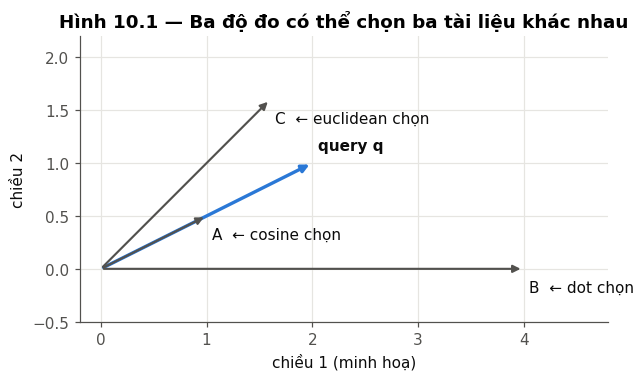

,cosine ↑,euclidean ↓,dot ↑,‖d‖
Tài liệu,,,,
"A (cùng hướng, ngắn)",1.000,1.118,2.5,1.118
"B (lệch hướng, dài)",0.894,2.236,8.0,4.000
C (gần về vị trí),0.949,0.721,4.8,2.263


Đã lưu hình: /content/drive/MyDrive/Colab_Notebooks/Ki_2/IRS/figures/10_2_phan_bo_norm.png


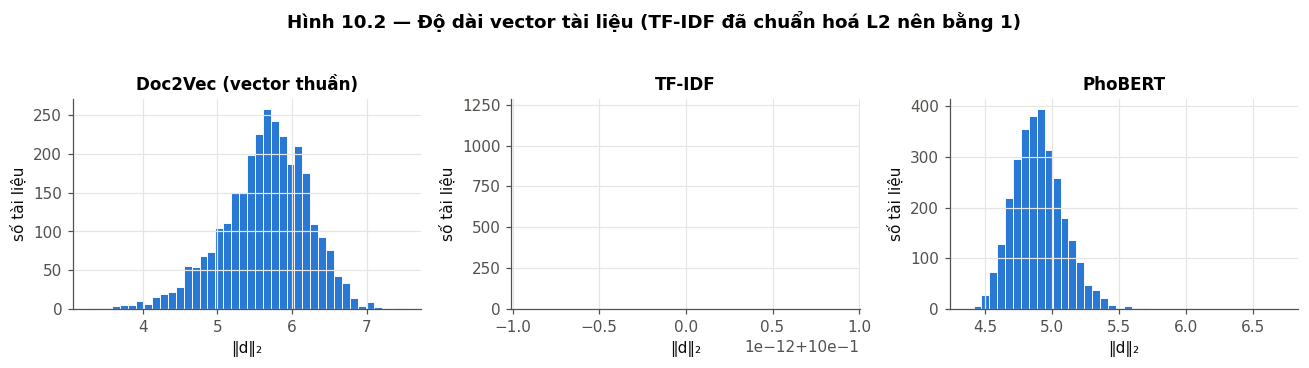

,norm min,norm median,norm max,max / min
Phương pháp,,,,
Doc2Vec (vector thuần),3.274,5.687,7.518,2.296
TF-IDF,1.000,1.000,1.000,1.000
PhoBERT,4.355,4.888,6.714,1.542


Đã lưu hình: /content/drive/MyDrive/Colab_Notebooks/Ki_2/IRS/figures/10_3_cosine_vs_dot_euclid.png


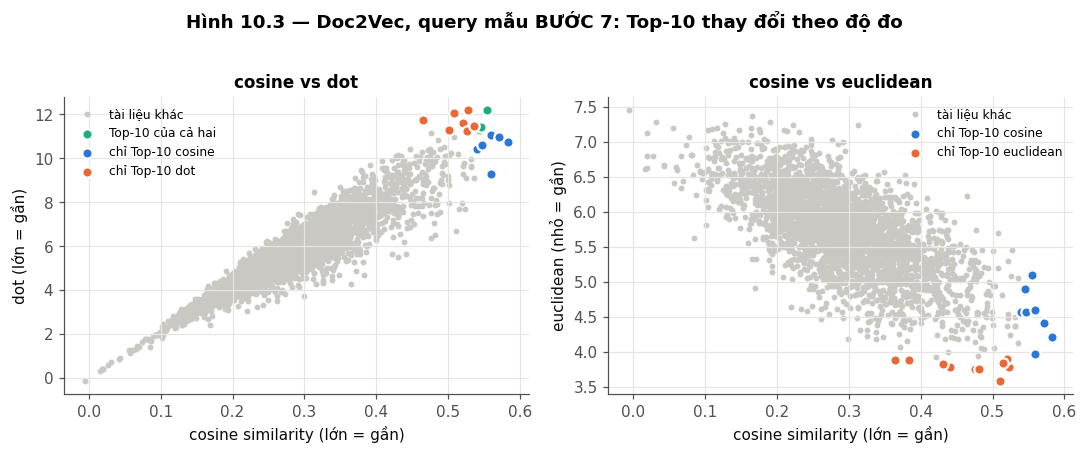

{'Top-10 trùng cosine ∩ dot': 3, 'Top-10 trùng cosine ∩ euclidean': 0}


In [16]:
# ============================================================
# BƯỚC 10A — STYLE HÌNH + MINH HOẠ 3 ĐỘ ĐO
# ============================================================
import matplotlib.pyplot as plt

FIGURE_DIR = PROJECT_DIR / "figures"
FIGURE_DIR.mkdir(parents=True, exist_ok=True)

# Bảng màu categorical cố định thứ tự (đã kiểm tra mù màu, xem chú thích cuối cell)
SERIES_COLORS = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300"]
CONTEXT_GRAY = "#c9c8c3"
TEXT_PRIMARY = "#0b0b0b"
TEXT_SECONDARY = "#52514e"

# Màu cố định theo phương pháp / độ đo (không đổi giữa các hình)
METHOD_COLORS = {
    "BM25 thuần (tham chiếu)": SERIES_COLORS[3],
    "TF-IDF": SERIES_COLORS[1],
    "Doc2Vec (vector thuần)": SERIES_COLORS[0],
    "PhoBERT": SERIES_COLORS[2],
    HYBRID_METHOD: SERIES_COLORS[4],
}
MEASURE_COLORS = dict(zip(SIMILARITY_MEASURES, SERIES_COLORS[:3]))

plt.rcParams.update({
    "figure.dpi": 110,
    "savefig.dpi": 200,
    "figure.facecolor": "white",
    "axes.facecolor": "white",
    "axes.edgecolor": TEXT_SECONDARY,
    "axes.labelcolor": TEXT_PRIMARY,
    "axes.titlesize": 12,
    "axes.titleweight": "bold",
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.grid": True,
    "grid.color": "#e6e5e1",
    "grid.linewidth": 0.8,
    "xtick.color": TEXT_SECONDARY,
    "ytick.color": TEXT_SECONDARY,
    "legend.frameon": False,
    "font.size": 10,
})


def save_figure(fig, name):
    path = FIGURE_DIR / f"{name}.png"
    fig.savefig(path, bbox_inches="tight")
    print("Đã lưu hình:", path)


# ------------------------------------------------------------
# Hình 10.1 — Minh hoạ 2D: mỗi độ đo chọn một tài liệu khác nhau
# (số liệu minh hoạ do tác giả đặt, KHÔNG phải dữ liệu thực nghiệm)
# ------------------------------------------------------------
toy_query = np.array([2.0, 1.0])
toy_docs = {
    "A (cùng hướng, ngắn)": np.array([1.0, 0.5]),
    "B (lệch hướng, dài)": np.array([4.0, 0.0]),
    "C (gần về vị trí)": np.array([1.6, 1.6]),
}

toy_rows = []
for name, vec in toy_docs.items():
    toy_rows.append({
        "Tài liệu": name,
        "cosine ↑": toy_query @ vec / (np.linalg.norm(toy_query) * np.linalg.norm(vec)),
        "euclidean ↓": np.linalg.norm(toy_query - vec),
        "dot ↑": toy_query @ vec,
        "‖d‖": np.linalg.norm(vec),
    })
df_toy = pd.DataFrame(toy_rows).set_index("Tài liệu")

toy_winner = {
    "cosine": df_toy["cosine ↑"].idxmax(),
    "euclidean": df_toy["euclidean ↓"].idxmin(),
    "dot": df_toy["dot ↑"].idxmax(),
}

fig, ax = plt.subplots(figsize=(6.2, 4.2))
ax.annotate("", xy=toy_query, xytext=(0, 0),
            arrowprops=dict(arrowstyle="-|>", color=SERIES_COLORS[0], lw=2.2))
ax.text(*(toy_query + [0.05, 0.12]), "query q", color=TEXT_PRIMARY, fontweight="bold")

for name, vec in toy_docs.items():
    ax.annotate("", xy=vec, xytext=(0, 0),
                arrowprops=dict(arrowstyle="-|>", color=TEXT_SECONDARY, lw=1.4))
    chosen_by = [m for m, w in toy_winner.items() if w == name]
    label = name.split(" ")[0] + (f"  ← {', '.join(chosen_by)} chọn" if chosen_by else "")
    ax.text(vec[0] + 0.05, vec[1] - 0.22, label, color=TEXT_PRIMARY)

ax.set_xlim(-0.2, 4.8)
ax.set_ylim(-0.5, 2.2)
ax.set_aspect("equal")
ax.set_title("Hình 10.1 — Ba độ đo có thể chọn ba tài liệu khác nhau")
ax.set_xlabel("chiều 1 (minh hoạ)")
ax.set_ylabel("chiều 2")
save_figure(fig, "10_1_minh_hoa_do_do")
plt.show()

display(df_toy.round(3))


# ------------------------------------------------------------
# Hình 10.2 — Phân bố độ dài (L2 norm) vector tài liệu theo phương pháp
# Norm khác nhau nhiều  =>  dot / euclidean bị lệch so với cosine
# ------------------------------------------------------------
def doc_norms(matrix):
    if sp.issparse(matrix):
        return np.sqrt(np.asarray(matrix.multiply(matrix).sum(axis=1)).ravel())
    return np.linalg.norm(matrix, axis=1)


norm_rows = []
fig, axes = plt.subplots(1, len(VECTOR_METHODS), figsize=(4 * len(VECTOR_METHODS), 3.2))
for ax, (method, spec) in zip(np.atleast_1d(axes), VECTOR_METHODS.items()):
    norms = doc_norms(spec["matrix"])
    ax.hist(norms, bins=40, color=SERIES_COLORS[0], edgecolor="white", linewidth=0.6)
    ax.set_title(method, fontsize=11)
    ax.set_xlabel("‖d‖₂")
    ax.set_ylabel("số tài liệu")
    norm_rows.append({
        "Phương pháp": method,
        "norm min": norms.min(),
        "norm median": np.median(norms),
        "norm max": norms.max(),
        "max / min": norms.max() / max(norms.min(), 1e-12),
    })
fig.suptitle("Hình 10.2 — Độ dài vector tài liệu (TF-IDF đã chuẩn hoá L2 nên bằng 1)",
             fontweight="bold", y=1.03)
fig.tight_layout()
save_figure(fig, "10_2_phan_bo_norm")
plt.show()

display(pd.DataFrame(norm_rows).set_index("Phương pháp").round(3))


# ------------------------------------------------------------
# Hình 10.3 — Một query thật, Doc2Vec: cosine vs dot / euclidean trên 3.000 tài liệu
# ------------------------------------------------------------
MEASURE_DEMO_QUERY = test_query
spec = VECTOR_METHODS["Doc2Vec (vector thuần)"]
demo_vector = spec["encode"](MEASURE_DEMO_QUERY)
demo_scores = {m: similarity_scores(spec["matrix"], demo_vector, m) for m in SIMILARITY_MEASURES}
top_by = {m: set(rank_order(demo_scores[m], m)[:V64_TOP_K]) for m in SIMILARITY_MEASURES}

fig, axes = plt.subplots(1, 2, figsize=(10, 4))
for ax, other in zip(axes, ["dot", "euclidean"]):
    ax.scatter(demo_scores["cosine"], demo_scores[other], s=8, color=CONTEXT_GRAY,
               label="tài liệu khác", rasterized=True)
    only_cos = sorted(top_by["cosine"] - top_by[other])
    only_other = sorted(top_by[other] - top_by["cosine"])
    both = sorted(top_by["cosine"] & top_by[other])
    for idx, color, label in [
        (both, SERIES_COLORS[2], "Top-10 của cả hai"),
        (only_cos, SERIES_COLORS[0], "chỉ Top-10 cosine"),
        (only_other, SERIES_COLORS[1], f"chỉ Top-10 {other}"),
    ]:
        if idx:
            ax.scatter(demo_scores["cosine"][idx], demo_scores[other][idx], s=46,
                       color=color, edgecolor="white", linewidth=1.5, label=label, zorder=3)
    ax.set_xlabel("cosine similarity (lớn = gần)")
    ax.set_ylabel(f"{other} ({'nhỏ' if other == 'euclidean' else 'lớn'} = gần)")
    ax.set_title(f"cosine vs {other}", fontsize=11)
    ax.legend(loc="best", fontsize=8)
fig.suptitle("Hình 10.3 — Doc2Vec, query mẫu BƯỚC 7: Top-10 thay đổi theo độ đo",
             fontweight="bold", y=1.02)
fig.tight_layout()
save_figure(fig, "10_3_cosine_vs_dot_euclid")
plt.show()

print({f"Top-10 trùng cosine ∩ {m}": len(top_by["cosine"] & top_by[m]) for m in ["dot", "euclidean"]})
# Palette: thứ tự slot 1-6 của bảng màu tham chiếu (blue, orange, aqua, yellow, magenta, green),
# kiểm tra bằng validator mù màu: ΔE kề nhau >= 9.1 (CVD), >= 19.6 (bình thường).
# Aqua/yellow/magenta có tương phản < 3:1 trên nền trắng -> mỗi hình đều kèm bảng số.
# Scatter chỉ dùng tối đa 3 màu (3 slot đầu đạt yêu cầu khi xét mọi cặp).

### BƯỚC 10B — Đánh giá thực nghiệm theo độ đo

Mỗi phương pháp vector × mỗi độ đo được chạy trên **cùng bộ query KI20 / KI60 / CAT** và cùng định nghĩa chỉ số của BƯỚC 7B. Dòng Doc2Vec + cosine phải trùng dòng (1) của bảng ablation khi cả hai được tính trong cùng một phiên (cell in ra để kiểm tra). Kết quả được cache trong `CACHE_DIR`.

**Lưu ý về tính lặp lại:** `infer_vector` của gensim khởi tạo vector query bằng `hash()` của Python (`pseudorandom_weak_vector` trong `gensim/models/keyedvectors.py`), giá trị này thay đổi giữa các phiên do `PYTHONHASHSEED`. Vì vậy `model_v5.random.seed(42)` chỉ cố định kết quả **trong một phiên**; giữa hai phiên, các chỉ số dựa trên Doc2Vec có thể lệch khoảng 0.01 (đo được trên máy test: KI20 MRR 0.615–0.621).

Xong: Doc2Vec (vector thuần) (30s)
Xong: TF-IDF (22s)
Xong: PhoBERT (291s)
Đã lưu: /content/drive/MyDrive/Colab_Notebooks/Ki_2/IRS/irs_cache_v5/method_eval_9ec6556cba.csv
Doc2Vec cosine KI20 MRR — BƯỚC 10B: 0.616 | ablation (1): 0.616


KI20 MRR  KI60 MRR  CAT P@10 (proxy)  \
Phương pháp            Độ đo                                             
Doc2Vec (vector thuần) cosine        0.616     0.973             0.685   
                       euclidean     0.058     0.560             0.571   
                       dot           0.571     0.942             0.626   
TF-IDF                 cosine        0.729     0.983             0.686   
                       euclidean     0.729     0.983             0.686   
                       dot           0.729     0.983             0.686   
PhoBERT                cosine        0.578     0.823             0.765   
                       euclidean     0.563     0.839             0.764   
                       dot           0.351     0.541             0.644   

                                  Latency TB (ms)  
Phương pháp            Độ đo                       
Doc2Vec (vector thuần) cosine              90.683  
                       euclidean           90.058  
                       dot                 83.414  
TF-IDF                 cosine              57.205  
                       euclidean           54.451  
                       dot                 50.955  
PhoBERT                cosine             935.951  
                       euclidean          945.472  
                       dot                919.873

Đã lưu hình: /content/drive/MyDrive/Colab_Notebooks/Ki_2/IRS/figures/10_4_so_sanh_do_do.png


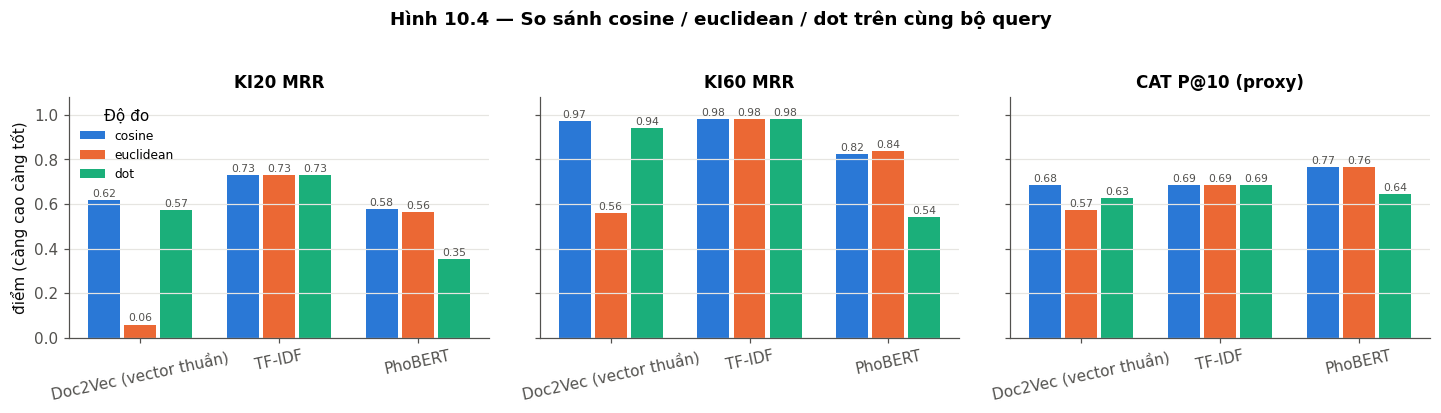

In [17]:
# ============================================================
# BƯỚC 10B — ĐÁNH GIÁ PHƯƠNG PHÁP × ĐỘ ĐO
# Cùng bộ query KI20 / KI60 / CAT và cùng định nghĩa chỉ số với BƯỚC 7B,
# nên so sánh được trực tiếp với bảng ablation (Hybrid V6.4, BM25).
# ============================================================

METHOD_EVAL_KEY = hashlib.md5(
    json.dumps([
        ABLATION_KEY,
        sorted(VECTOR_METHODS),
        PHOBERT_FINGERPRINT if PHOBERT_AVAILABLE else None,
        SIMILARITY_MEASURES,
        "method-eval-v1"
    ]).encode("utf-8")
).hexdigest()[:10]

METHOD_EVAL_CACHE = CACHE_DIR / f"method_eval_{METHOD_EVAL_KEY}.csv"


def evaluate_vector_method(method):
    """Encode mỗi query 1 lần, xếp hạng bằng cả 3 độ đo."""
    spec = VECTOR_METHODS[method]
    stats = {m: defaultdict(list) for m in SIMILARITY_MEASURES}
    seconds = {m: 0.0 for m in SIMILARITY_MEASURES}
    n_queries = 0

    def ranked_for(query_text, k):
        nonlocal n_queries
        n_queries += 1
        t0 = time.perf_counter()
        try:
            query_vector = spec["encode"](query_text)
        except ValueError:
            query_vector = None
        encode_s = time.perf_counter() - t0

        out = {}
        for m in SIMILARITY_MEASURES:
            t0 = time.perf_counter()
            ids = [] if query_vector is None else rank_vector(spec, query_vector, m, k)[0].tolist()
            seconds[m] += encode_s + time.perf_counter() - t0
            out[m] = ids
        return out

    for set_name, queries in QUERY_SETS.items():
        for query_text, target_id in queries:
            for m, ranked in ranked_for(query_text, V64_TOP_K).items():
                rank = ranked.index(target_id) + 1 if target_id in ranked else None
                stats[m][f"{set_name} R@1"].append(rank == 1)
                stats[m][f"{set_name} R@10"].append(rank is not None)
                stats[m][f"{set_name} MRR"].append(1 / rank if rank else 0.0)

    for query_text, self_id in CAT_QUERIES:
        for m, ranked in ranked_for(query_text, V64_TOP_K + 1).items():
            ranked = [d for d in ranked if d != self_id][:V64_TOP_K]
            stats[m]["CAT P@10 (proxy)"].append(
                np.mean([doc_category[d] == doc_category[self_id] for d in ranked]) if ranked else 0.0
            )

    rows = []
    for m in SIMILARITY_MEASURES:
        row = {"Phương pháp": method, "Độ đo": m}
        row.update({k: float(np.mean(v)) for k, v in stats[m].items()})
        row["Latency TB (ms)"] = 1000 * seconds[m] / n_queries
        rows.append(row)
    return rows


if METHOD_EVAL_CACHE.is_file() and not FORCE_REBUILD:
    df_method_eval = pd.read_csv(METHOD_EVAL_CACHE)
    print("Đã load đánh giá phương pháp × độ đo từ cache:", METHOD_EVAL_CACHE)
else:
    rows = []
    for method in VECTOR_METHODS:
        t0 = time.perf_counter()
        rows += evaluate_vector_method(method)
        print(f"Xong: {method} ({time.perf_counter() - t0:.0f}s)")
    df_method_eval = pd.DataFrame(rows)
    df_method_eval.to_csv(METHOD_EVAL_CACHE, index=False)
    print("Đã lưu:", METHOD_EVAL_CACHE)

# Kiểm tra nhất quán: Doc2Vec cosine ở đây phải khớp dòng (1) của ablation
_d2v_cos = df_method_eval.query("`Phương pháp` == 'Doc2Vec (vector thuần)' and `Độ đo` == 'cosine'")
_abl_core = df_ablation.set_index("Cấu hình").loc["(1) Doc2Vec cosine (lõi)"]
print("Doc2Vec cosine KI20 MRR — BƯỚC 10B:", round(float(_d2v_cos["KI20 MRR"].iloc[0]), 3),
      "| ablation (1):", round(float(_abl_core["KI20 MRR"]), 3))
# Hai số này trùng nhau khi tính trong cùng một phiên. Nếu một bảng được load từ cache
# của phiên khác, có thể lệch ~0.01: gensim khởi tạo vector của infer_vector bằng
# hash(seed_string) của Python (gensim/models/keyedvectors.py, pseudorandom_weak_vector),
# mà hash() của chuỗi thay đổi giữa các phiên (PYTHONHASHSEED).

MEASURE_TABLE_COLS = ["KI20 MRR", "KI60 MRR", "CAT P@10 (proxy)", "Latency TB (ms)"]
display(
    df_method_eval
    .set_index(["Phương pháp", "Độ đo"])[MEASURE_TABLE_COLS]
    .round(3)
)

# ------------------------------------------------------------
# Hình 10.4 — Ảnh hưởng của độ đo, theo từng phương pháp
# ------------------------------------------------------------
metric_cols = ["KI20 MRR", "KI60 MRR", "CAT P@10 (proxy)"]
methods = list(VECTOR_METHODS)
bar_w = 0.26
x = np.arange(len(methods))

fig, axes = plt.subplots(1, len(metric_cols), figsize=(4.4 * len(metric_cols), 3.6), sharey=True)
for ax, metric in zip(axes, metric_cols):
    for j, m in enumerate(SIMILARITY_MEASURES):
        values = [
            float(df_method_eval.query("`Phương pháp` == @meth and `Độ đo` == @m")[metric].iloc[0])
            for meth in methods
        ]
        bars = ax.bar(x + (j - 1) * bar_w, values, width=bar_w - 0.03,
                      color=MEASURE_COLORS[m], label=m)
        ax.bar_label(bars, fmt="%.2f", fontsize=7, color=TEXT_SECONDARY, padding=1)
    ax.set_xticks(x, methods, rotation=12)
    ax.set_title(metric, fontsize=11)
    ax.set_ylim(0, 1.08)
    ax.grid(axis="x", visible=False)
axes[0].set_ylabel("điểm (càng cao càng tốt)")
axes[0].legend(title="Độ đo", loc="upper left", fontsize=8)
fig.suptitle("Hình 10.4 — So sánh cosine / euclidean / dot trên cùng bộ query",
             fontweight="bold", y=1.03)
fig.tight_layout()
save_figure(fig, "10_4_so_sanh_do_do")
plt.show()

## BƯỚC 11 — Bảng và hình cho tiểu luận

Các bảng/hình dưới đây được tính từ dữ liệu và model đã có trong notebook, lưu PNG vào `PROJECT_DIR/figures/` (200 dpi):

| Mục | Nội dung |
|---|---|
| Bảng 11.1 · Hình 11.1 | Thống kê dataset, phân bố số bài theo category |
| Hình 11.2 · 11.3 | Phân bố độ dài văn bản (số từ gốc, số token sau preprocessing), theo category |
| Bảng 11.2 · Hình 11.4 | Thời gian train / xây chỉ mục của từng thành phần |
| Bảng 11.3 · Hình 11.5 | t-SNE và UMAP của document vectors (Doc2Vec, TF-IDF, PhoBERT), tô màu theo category + silhouette score |
| Bảng 11.4 · Hình 11.6 · 11.7 | So sánh các phương pháp (chất lượng truy hồi và latency) |

Ghi chú khi đưa vào tiểu luận:
- **Thời gian train Doc2Vec** được ghi khi train ở BƯỚC 4. Nếu model được load từ cache cũ (chưa có thời gian), cell sẽ train một bản tạm với cùng tham số để đo (`MEASURE_TRAIN_TIME_IF_MISSING = True`), không ghi đè model đang dùng. Thời gian **phụ thuộc phần cứng** (CPU/GPU của Colab), cần ghi rõ cấu hình máy khi trích dẫn.
- **PhoBERT không được train** trong notebook: số liệu là thời gian *encode* 3.000 tài liệu bằng model pre-trained.
- **t-SNE/UMAP** chỉ là phép chiếu 2D để quan sát; khoảng cách trên hình không bảo toàn khoảng cách gốc. Silhouette score (cosine, tính trên vector gốc, nhãn = category) bổ sung một con số định lượng cho mức tách cụm.
- Với 10 category, mỗi hình t-SNE/UMAP vẽ dạng **small multiples**: mỗi ô tô màu một category trên nền các điểm còn lại, tránh dùng 10 màu khó phân biệt (đặc biệt với người mù màu).
- Bảng so sánh phương pháp dùng **cùng bộ query tự sinh** của BƯỚC 7B (không có nhãn do người gán), nên mang tính tham khảo; xem hạn chế đã nêu ở BƯỚC 7B.

Bảng 11.1 — Thống kê dataset


,Giá trị
Số tài liệu,3000.0
Số category,10.0
Số từ / bài — trung bình,479.3
Số từ / bài — trung vị,372.0
Số từ / bài — min,53.0
Số từ / bài — max,6387.0
Token sau preprocessing / bài — trung bình,167.5
Token sau preprocessing / bài — trung vị,131.0
Từ vựng Doc2Vec (min_count = 2),21187.0
Từ vựng TF-IDF / BM25,47315.0


Đã lưu hình: /content/drive/MyDrive/Colab_Notebooks/Ki_2/IRS/figures/11_1_phan_bo_category.png


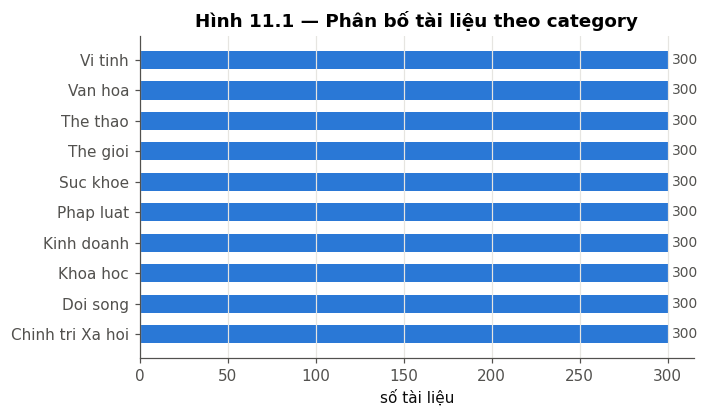

Đã lưu hình: /content/drive/MyDrive/Colab_Notebooks/Ki_2/IRS/figures/11_2_phan_bo_do_dai.png


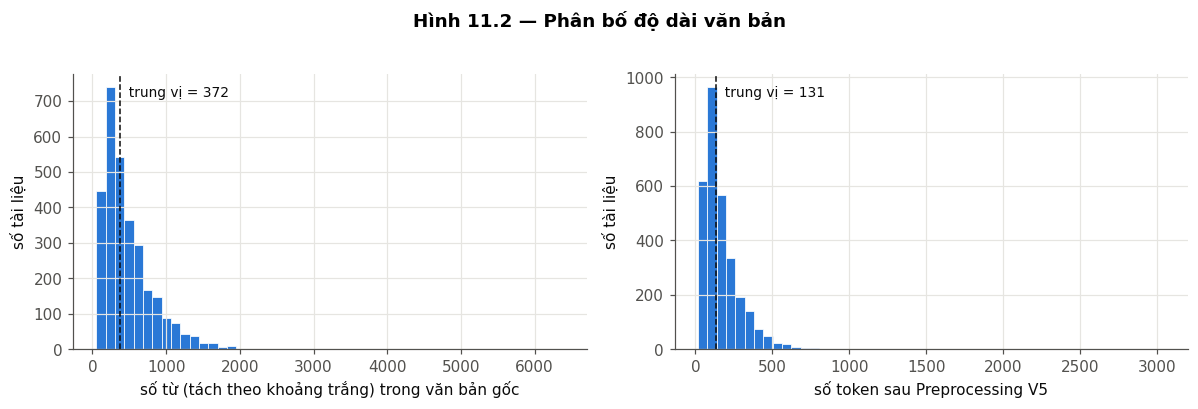

Đã lưu hình: /content/drive/MyDrive/Colab_Notebooks/Ki_2/IRS/figures/11_3_do_dai_theo_category.png


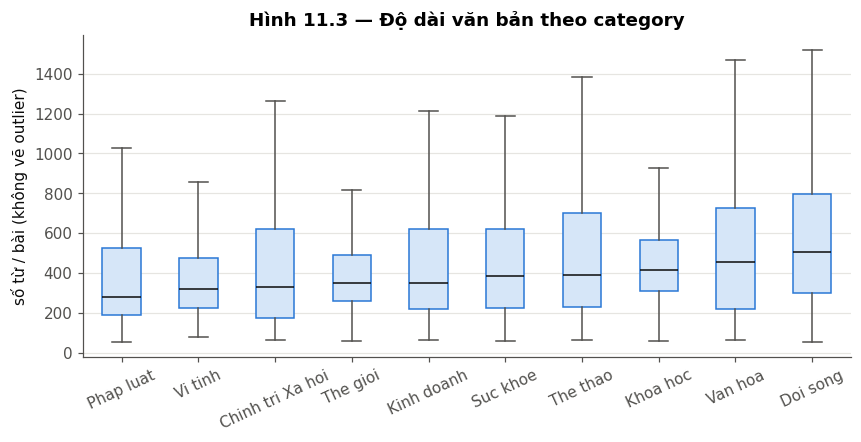

n_words_raw        n_tokens_v5       
                        mean median        mean median
category                                              
Chinh tri Xa hoi       476.0  330.0       176.0  127.0
Doi song               597.0  504.0       193.0  158.0
Khoa hoc               475.0  414.0       156.0  134.0
Kinh doanh             470.0  348.0       162.0  124.0
Phap luat              394.0  278.0       148.0  108.0
Suc khoe               475.0  384.0       174.0  140.0
The gioi               428.0  348.0       150.0  124.0
The thao               515.0  388.0       192.0  141.0
Van hoa                560.0  453.0       182.0  149.0
Vi tinh                404.0  318.0       142.0  108.0

In [18]:
# ============================================================
# BƯỚC 11A — DATASET: THỐNG KÊ, PHÂN BỐ CATEGORY, PHÂN BỐ ĐỘ DÀI
# ============================================================

df_docs["n_words_raw"] = df_docs["text_raw"].str.split().str.len()
df_docs["n_tokens_v5"] = df_docs["tokens_v5"].str.len()

dataset_summary = pd.Series({
    "Số tài liệu": len(df_docs),
    "Số category": df_docs[CATEGORY_COL].nunique(),
    "Số từ / bài — trung bình": df_docs["n_words_raw"].mean(),
    "Số từ / bài — trung vị": df_docs["n_words_raw"].median(),
    "Số từ / bài — min": df_docs["n_words_raw"].min(),
    "Số từ / bài — max": df_docs["n_words_raw"].max(),
    "Token sau preprocessing / bài — trung bình": df_docs["n_tokens_v5"].mean(),
    "Token sau preprocessing / bài — trung vị": df_docs["n_tokens_v5"].median(),
    "Từ vựng Doc2Vec (min_count = 2)": len(model_v5.wv),
    "Từ vựng TF-IDF / BM25": TFIDF_MATRIX.shape[1],
    "Từ điển âm tiết (sửa dấu)": len(syllable_vocab),
}, name="Giá trị")

print("Bảng 11.1 — Thống kê dataset")
display(dataset_summary.to_frame().round(1))

# ---------------- Hình 11.1: số bài theo category ----------------
category_counts = df_docs[CATEGORY_COL].value_counts().sort_values()

fig, ax = plt.subplots(figsize=(6.5, 3.8))
bars = ax.barh(category_counts.index, category_counts.values, height=0.6, color=SERIES_COLORS[0])
ax.bar_label(bars, padding=3, color=TEXT_SECONDARY, fontsize=9)
ax.set_xlabel("số tài liệu")
ax.grid(axis="y", visible=False)
ax.set_title("Hình 11.1 — Phân bố tài liệu theo category")
save_figure(fig, "11_1_phan_bo_category")
plt.show()

# ---------------- Hình 11.2: phân bố độ dài ----------------
fig, axes = plt.subplots(1, 2, figsize=(11, 3.6))
for ax, col, label in [
    (axes[0], "n_words_raw", "số từ (tách theo khoảng trắng) trong văn bản gốc"),
    (axes[1], "n_tokens_v5", "số token sau Preprocessing V5"),
]:
    values = df_docs[col]
    ax.hist(values, bins=50, color=SERIES_COLORS[0], edgecolor="white", linewidth=0.5)
    ax.axvline(values.median(), color=TEXT_PRIMARY, linestyle="--", linewidth=1)
    ax.text(values.median(), ax.get_ylim()[1] * 0.92, f"  trung vị = {values.median():.0f}",
            color=TEXT_PRIMARY, fontsize=9)
    ax.set_xlabel(label)
    ax.set_ylabel("số tài liệu")
fig.suptitle("Hình 11.2 — Phân bố độ dài văn bản", fontweight="bold", y=1.02)
fig.tight_layout()
save_figure(fig, "11_2_phan_bo_do_dai")
plt.show()

# ---------------- Hình 11.3: độ dài theo category ----------------
order = df_docs.groupby(CATEGORY_COL)["n_words_raw"].median().sort_values().index
fig, ax = plt.subplots(figsize=(9, 3.8))
ax.boxplot(
    [df_docs.loc[df_docs[CATEGORY_COL] == c, "n_words_raw"] for c in order],
    showfliers=False,
    patch_artist=True,
    boxprops=dict(facecolor="#d6e6f8", edgecolor=SERIES_COLORS[0]),
    medianprops=dict(color=TEXT_PRIMARY),
    whiskerprops=dict(color=TEXT_SECONDARY),
    capprops=dict(color=TEXT_SECONDARY),
)
ax.set_xticks(range(1, len(order) + 1), list(order))
ax.set_ylabel("số từ / bài (không vẽ outlier)")
ax.tick_params(axis="x", rotation=25)
ax.grid(axis="x", visible=False)
ax.set_title("Hình 11.3 — Độ dài văn bản theo category")
save_figure(fig, "11_3_do_dai_theo_category")
plt.show()

display(
    df_docs.groupby(CATEGORY_COL)[["n_words_raw", "n_tokens_v5"]]
    .agg(["mean", "median"])
    .round(0)
)

Model Doc2Vec được load từ cache cũ (chưa ghi thời gian train).
Train một bản tạm với cùng DOC2VEC_PARAMS để đo (không ghi đè model_v5)...
Bảng 11.2 — Thời gian train / xây chỉ mục
Phần cứng: x86_64 · 2 CPU threads · GPU: không dùng GPU


,Thành phần,Loại,Thời gian (s)
0,Preprocessing V5 (3.000 bài),tiền xử lý,NaN
1,Doc2Vec PV-DBOW (build_vocab + 40 epochs),train,207.27
2,TF-IDF fit,xây chỉ mục,2.44
3,BM25 index,xây chỉ mục,1.31
4,Bigram LM âm tiết (sửa dấu),xây chỉ mục,4.86
5,PhoBERT encode 3.000 bài (cpu),encode (không train),2845.66


Ô trống = cache cũ chưa ghi thời gian; đặt FORCE_REBUILD = True rồi chạy lại để đo.
Đã lưu hình: /content/drive/MyDrive/Colab_Notebooks/Ki_2/IRS/figures/11_4_thoi_gian_train.png


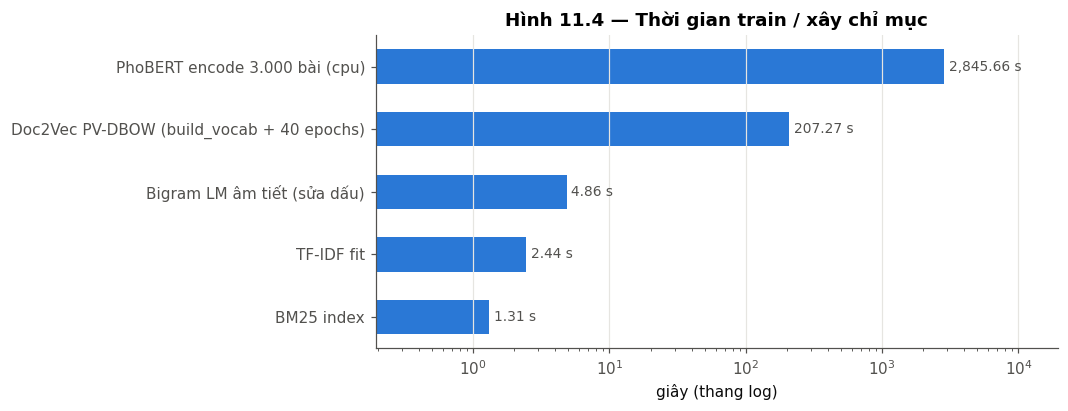

In [19]:
# ============================================================
# BƯỚC 11B — THỜI GIAN TRAIN / XÂY CHỈ MỤC
# ============================================================
import platform

MEASURE_TRAIN_TIME_IF_MISSING = True


def meta_seconds(meta_path):
    try:
        return json.loads(meta_path.read_text(encoding="utf-8")).get("seconds")
    except (OSError, ValueError):
        return None


doc2vec_train_seconds = meta_seconds(MODEL_META)

if doc2vec_train_seconds is None and MEASURE_TRAIN_TIME_IF_MISSING:
    print("Model Doc2Vec được load từ cache cũ (chưa ghi thời gian train).")
    print("Train một bản tạm với cùng DOC2VEC_PARAMS để đo (không ghi đè model_v5)...")
    _tagged = [
        TaggedDocument(words=row["tokens_v5"], tags=[row["doc_id"]])
        for _, row in df_docs.iterrows()
        if len(row["tokens_v5"]) > 0
    ]
    _t0 = time.perf_counter()
    _tmp_model = Doc2Vec(**DOC2VEC_PARAMS)
    _tmp_model.build_vocab(_tagged)
    _tmp_model.train(_tagged, total_examples=_tmp_model.corpus_count, epochs=_tmp_model.epochs)
    doc2vec_train_seconds = time.perf_counter() - _t0
    del _tmp_model, _tagged

    _meta = json.loads(MODEL_META.read_text(encoding="utf-8"))
    _meta["seconds"] = doc2vec_train_seconds
    MODEL_META.write_text(json.dumps(_meta), encoding="utf-8")

preprocess_seconds = meta_seconds(DF_DOCS_META)

gpu_name = (
    torch.cuda.get_device_name(0)
    if PHOBERT_AVAILABLE and torch.cuda.is_available()
    else "không dùng GPU"
)
hardware = f"{platform.processor() or platform.machine()} · {os.cpu_count()} CPU threads · GPU: {gpu_name}"

time_rows = [
    ("Preprocessing V5 (3.000 bài)", "tiền xử lý", preprocess_seconds),
    ("Doc2Vec PV-DBOW (build_vocab + 40 epochs)", "train", doc2vec_train_seconds),
    ("TF-IDF fit", "xây chỉ mục", BUILD_TIMES.get("TF-IDF fit")),
    ("BM25 index", "xây chỉ mục", BUILD_TIMES.get("BM25 index")),
    ("Bigram LM âm tiết (sửa dấu)", "xây chỉ mục", BUILD_TIMES.get("Spelling LM (âm tiết)")),
]
if PHOBERT_AVAILABLE:
    time_rows.append(
        (f"PhoBERT encode 3.000 bài ({PHOBERT_DEVICE})", "encode (không train)",
         BUILD_TIMES.get("PhoBERT encode corpus"))
    )

df_build_times = pd.DataFrame(time_rows, columns=["Thành phần", "Loại", "Thời gian (s)"])

print("Bảng 11.2 — Thời gian train / xây chỉ mục")
print("Phần cứng:", hardware)
display(df_build_times.round(2))

if df_build_times["Thời gian (s)"].isna().any():
    print("Ô trống = cache cũ chưa ghi thời gian; đặt FORCE_REBUILD = True rồi chạy lại để đo.")

_plot_times = df_build_times.dropna(subset=["Thời gian (s)"]).sort_values("Thời gian (s)")
fig, ax = plt.subplots(figsize=(8, 0.5 * len(_plot_times) + 1.2))
bars = ax.barh(_plot_times["Thành phần"], _plot_times["Thời gian (s)"], height=0.55,
               color=SERIES_COLORS[0])
ax.bar_label(bars, labels=[f"{v:,.2f} s" for v in _plot_times["Thời gian (s)"]],
             padding=3, color=TEXT_SECONDARY, fontsize=9)
ax.set_xscale("log")
ax.set_xlabel("giây (thang log)")
ax.grid(axis="y", visible=False)
ax.set_title("Hình 11.4 — Thời gian train / xây chỉ mục")
ax.margins(x=0.25)
save_figure(fig, "11_4_thoi_gian_train")
plt.show()

Đã lưu hình: /content/drive/MyDrive/Colab_Notebooks/Ki_2/IRS/figures/11_5_1_doc2vec_vector_thuan_t_sne.png


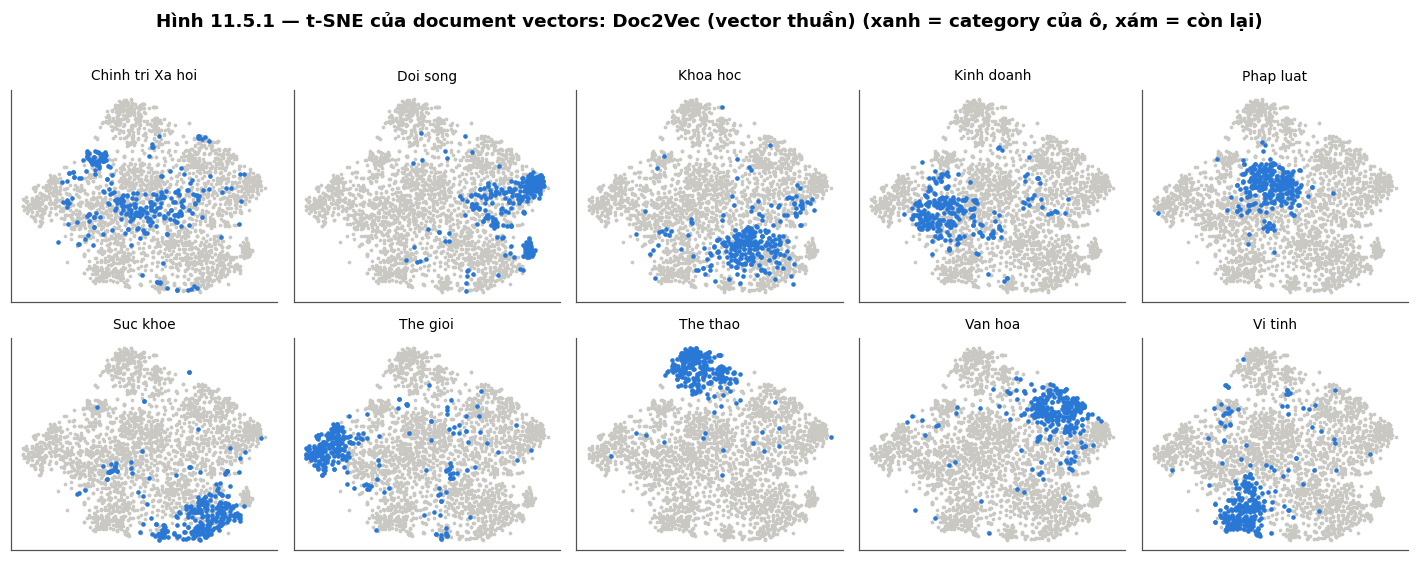

Doc2Vec (vector thuần) · t-SNE: 30.0s


/usr/local/lib/python3.13/dist-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


Đã lưu hình: /content/drive/MyDrive/Colab_Notebooks/Ki_2/IRS/figures/11_5_2_doc2vec_vector_thuan_umap.png


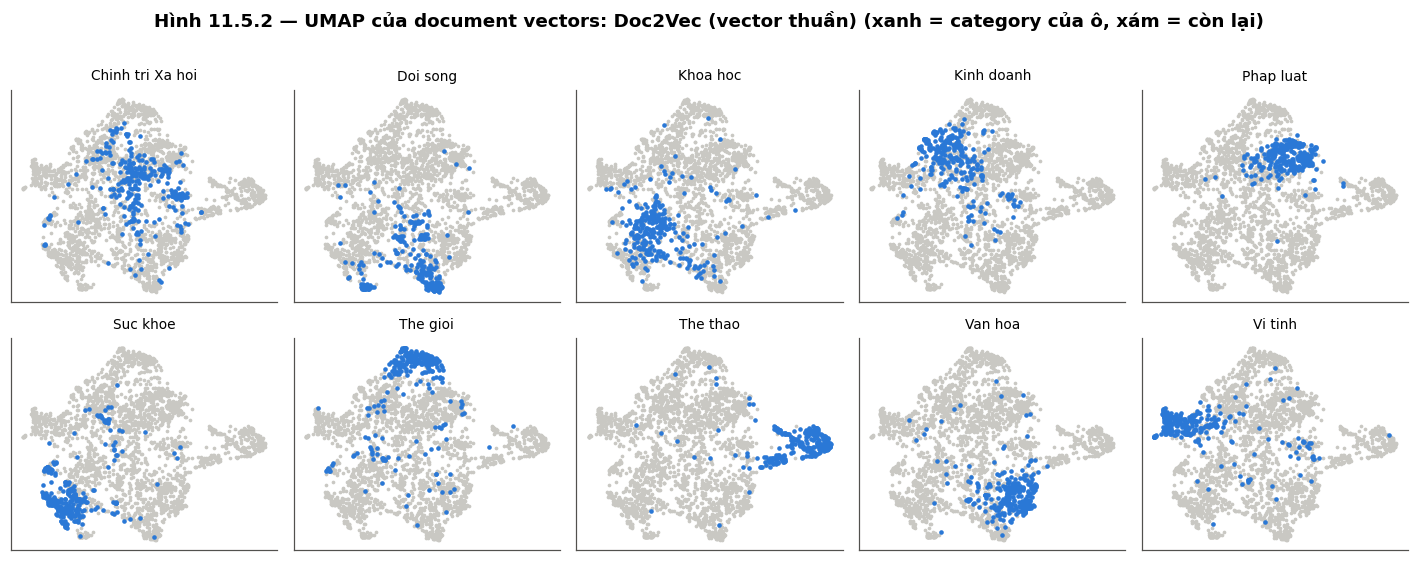

Doc2Vec (vector thuần) · UMAP: 31.2s
Đã lưu hình: /content/drive/MyDrive/Colab_Notebooks/Ki_2/IRS/figures/11_5_3_tf_idf_t_sne.png


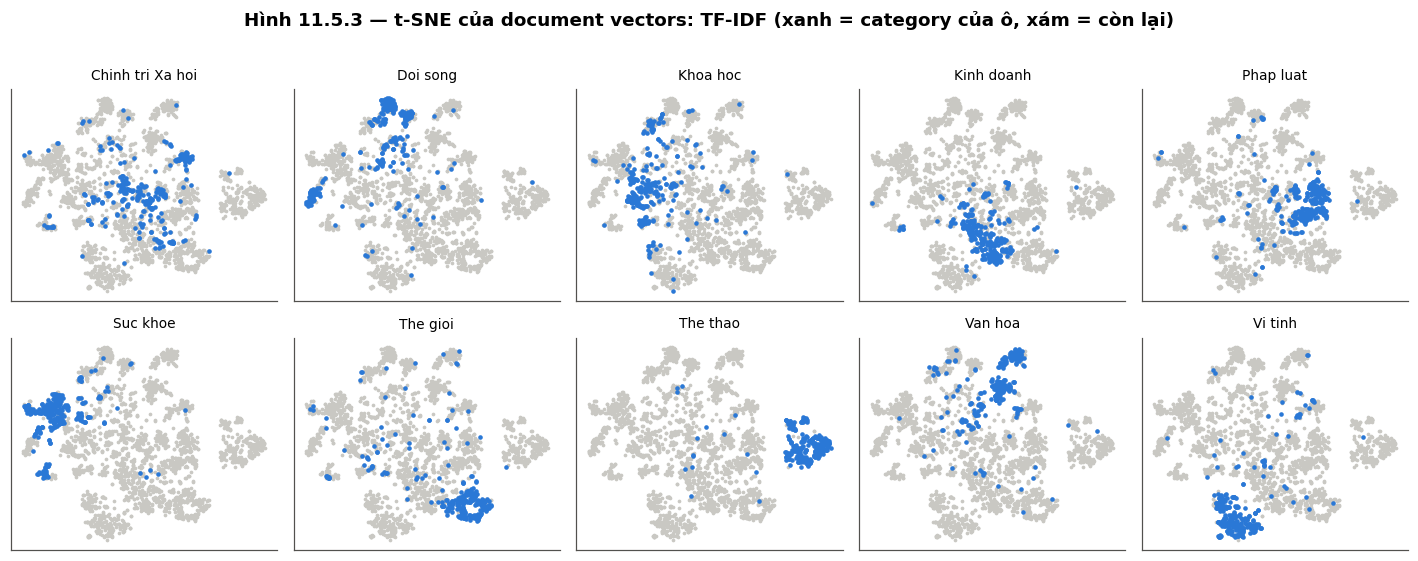

TF-IDF · t-SNE: 33.0s


/usr/local/lib/python3.13/dist-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


Đã lưu hình: /content/drive/MyDrive/Colab_Notebooks/Ki_2/IRS/figures/11_5_4_tf_idf_umap.png


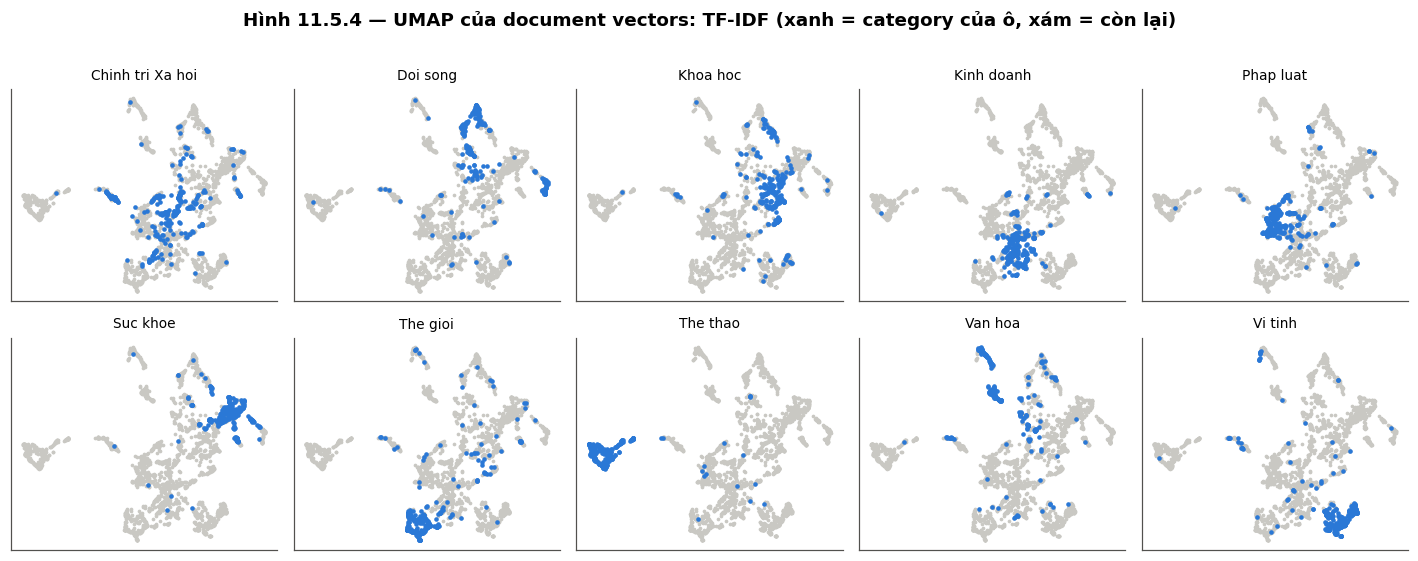

TF-IDF · UMAP: 23.3s
Đã lưu hình: /content/drive/MyDrive/Colab_Notebooks/Ki_2/IRS/figures/11_5_5_phobert_t_sne.png


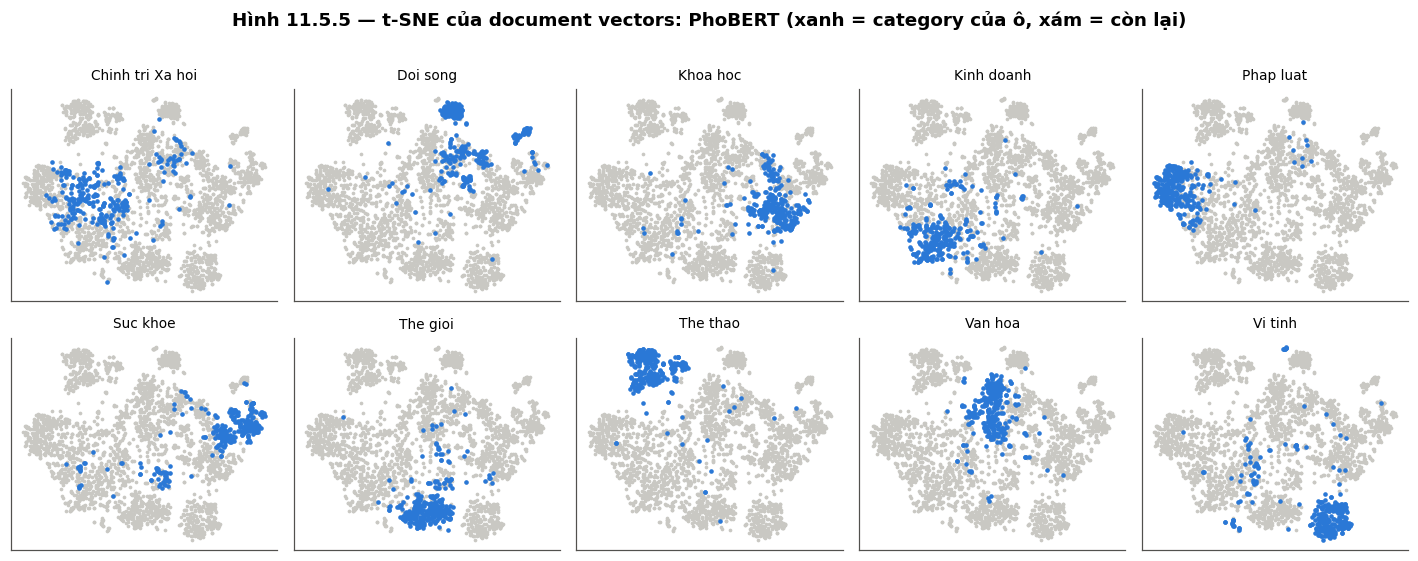

PhoBERT · t-SNE: 30.1s


/usr/local/lib/python3.13/dist-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


Đã lưu hình: /content/drive/MyDrive/Colab_Notebooks/Ki_2/IRS/figures/11_5_6_phobert_umap.png


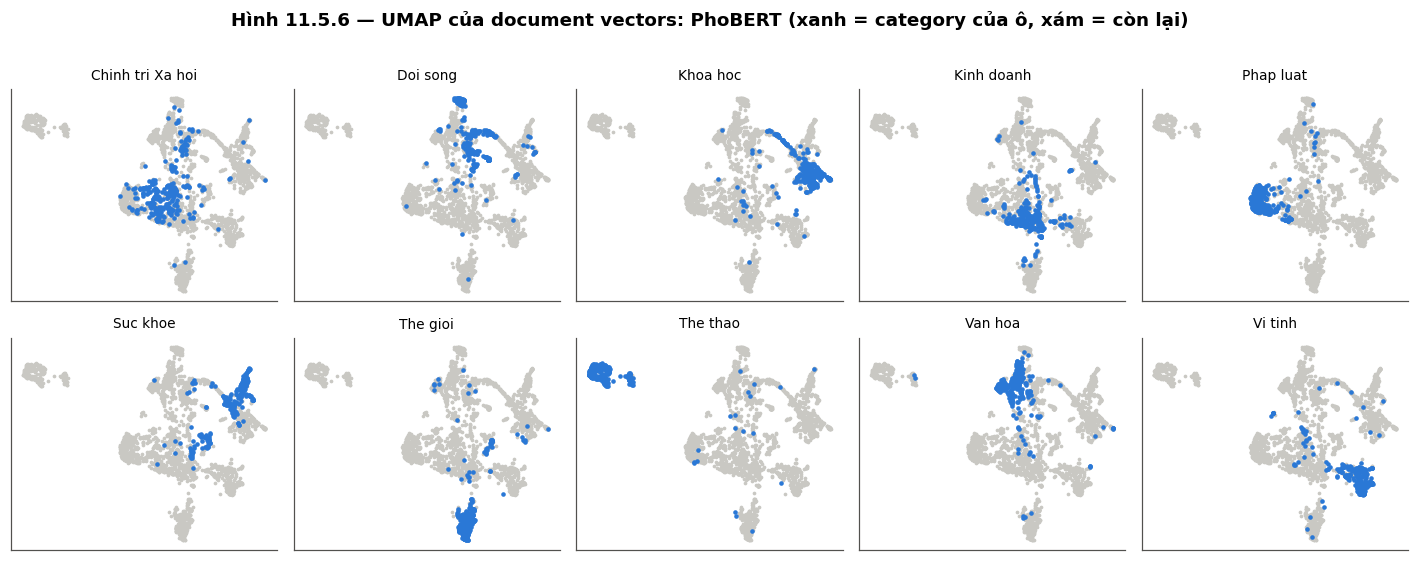

PhoBERT · UMAP: 18.0s
Bảng 11.3 — Silhouette score theo category (cao hơn = các category tách cụm rõ hơn)


,"Silhouette (cosine, vector gốc)"
Phương pháp,
Doc2Vec (vector thuần),0.0365
TF-IDF,0.0191
PhoBERT,0.0795


In [20]:
# ============================================================
# BƯỚC 11C — t-SNE / UMAP CỦA DOCUMENT VECTORS + SILHOUETTE
# ============================================================
!pip -q install umap-learn

from sklearn.decomposition import TruncatedSVD, PCA
from sklearn.manifold import TSNE
from sklearn.metrics import silhouette_score
from sklearn.preprocessing import normalize

try:
    import umap
    UMAP_AVAILABLE = True
except ImportError:
    UMAP_AVAILABLE = False
    print("Không có umap-learn -> chỉ vẽ t-SNE.")

PROJECTION_SEED = 42


def aligned_matrix(method):
    """Ma trận vector theo đúng thứ tự df_docs (Doc2Vec bỏ bài rỗng nên cần căn lại)."""
    spec = VECTOR_METHODS[method]
    position = {doc_id: i for i, doc_id in enumerate(spec["doc_ids"])}
    keep = df_docs["doc_id"].map(position).dropna().astype(int).to_numpy()
    matrix = spec["matrix"][keep]
    labels = df_docs.loc[df_docs["doc_id"].isin(position), CATEGORY_COL].to_numpy()
    return matrix, labels


def reduce_for_projection(matrix):
    """Giảm còn 50 chiều trước khi chiếu (TruncatedSVD cho sparse, PCA cho dense)."""
    if sp.issparse(matrix):
        reduced = TruncatedSVD(n_components=100, random_state=PROJECTION_SEED).fit_transform(matrix)
    else:
        reduced = np.asarray(matrix)
    reduced = normalize(reduced)           # chiếu theo hướng vector, khớp với cosine
    if reduced.shape[1] > 50:
        reduced = PCA(n_components=50, random_state=PROJECTION_SEED).fit_transform(reduced)
    return reduced


def projection_2d(method, reducer):
    key = hashlib.md5(
        json.dumps([MODEL_FINGERPRINT, METHOD_EVAL_KEY, method, reducer, "proj-v1"]).encode("utf-8")
    ).hexdigest()[:10]
    path = CACHE_DIR / f"proj_{key}.npy"
    if path.is_file() and not FORCE_REBUILD:
        return np.load(path)

    reduced = reduce_for_projection(aligned_matrix(method)[0])
    if reducer == "t-SNE":
        coords = TSNE(n_components=2, perplexity=30, init="pca",
                      random_state=PROJECTION_SEED).fit_transform(reduced)
    else:
        coords = umap.UMAP(n_components=2, n_neighbors=15, min_dist=0.1, metric="cosine",
                           random_state=PROJECTION_SEED).fit_transform(reduced)
    np.save(path, coords)
    return coords


REDUCERS = ["t-SNE"] + (["UMAP"] if UMAP_AVAILABLE else [])
CATEGORIES = sorted(df_docs[CATEGORY_COL].unique())

silhouette_rows = []
figure_no = 0

for method in VECTOR_METHODS:
    matrix, labels = aligned_matrix(method)
    silhouette_rows.append({
        "Phương pháp": method,
        "Silhouette (cosine, vector gốc)": silhouette_score(
            matrix, labels, metric="cosine", sample_size=None
        ),
    })

    for reducer in REDUCERS:
        figure_no += 1
        t0 = time.perf_counter()
        coords = projection_2d(method, reducer)

        n_cols = 5
        n_rows = int(np.ceil(len(CATEGORIES) / n_cols))
        fig, axes = plt.subplots(n_rows, n_cols, figsize=(2.6 * n_cols, 2.5 * n_rows),
                                 sharex=True, sharey=True)
        for ax, category in zip(axes.ravel(), CATEGORIES):
            mask = labels == category
            ax.scatter(coords[~mask, 0], coords[~mask, 1], s=2, color=CONTEXT_GRAY,
                       rasterized=True)
            ax.scatter(coords[mask, 0], coords[mask, 1], s=4, color=SERIES_COLORS[0],
                       rasterized=True)
            ax.set_title(category, fontsize=9, fontweight="normal")
            ax.set_xticks([])
            ax.set_yticks([])
            ax.grid(False)
        for ax in axes.ravel()[len(CATEGORIES):]:
            ax.axis("off")

        fig.suptitle(f"Hình 11.5.{figure_no} — {reducer} của document vectors: {method} "
                     f"(xanh = category của ô, xám = còn lại)", fontweight="bold", y=1.01)
        fig.tight_layout()
        safe = re.sub(r"[^a-z0-9]+", "_", strip_accents(f"{method}_{reducer}").lower()).strip("_")
        save_figure(fig, f"11_5_{figure_no}_{safe}")
        plt.show()
        print(f"{method} · {reducer}: {time.perf_counter() - t0:.1f}s")

df_silhouette = pd.DataFrame(silhouette_rows).set_index("Phương pháp")
print("Bảng 11.3 — Silhouette score theo category (cao hơn = các category tách cụm rõ hơn)")
display(df_silhouette.round(4))

### BƯỚC 11D — So sánh các phương pháp

Hybrid V6.4 và BM25 lấy từ bảng ablation (BƯỚC 7B); Doc2Vec thuần, TF-IDF, PhoBERT lấy từ BƯỚC 10B với độ đo cosine. Latency của Hybrid/BM25 tính từ cột thời gian của lần chạy ablation; nếu bảng ablation được load từ cache tạo trên máy khác, latency không so sánh trực tiếp được — khi đó xoá file `ablation_*.csv` để chạy lại trên cùng máy.

Bảng 11.4 — So sánh phương pháp (độ đo cosine; latency = thời gian TB mỗi query, gồm cả preprocessing query)


,KI20 R@1,KI20 R@10,KI20 MRR,KI60 R@1,KI60 R@10,KI60 MRR,CAT P@10 (proxy),Latency TB (ms)
Phương pháp,,,,,,,,
BM25 thuần (tham chiếu),0.95,1.00,0.973,0.99,1.00,0.995,0.774,79.454
Doc2Vec (vector thuần),0.52,0.82,0.616,0.95,1.00,0.973,0.685,90.683
TF-IDF,0.62,0.94,0.729,0.97,1.00,0.983,0.686,57.205
PhoBERT,0.49,0.77,0.578,0.78,0.91,0.823,0.765,935.951
Doc2Vec Hybrid V6.4 (hệ thống chính),0.85,0.97,0.895,0.99,1.00,0.995,0.833,59.302


Đã lưu hình: /content/drive/MyDrive/Colab_Notebooks/Ki_2/IRS/figures/11_6_so_sanh_phuong_phap.png


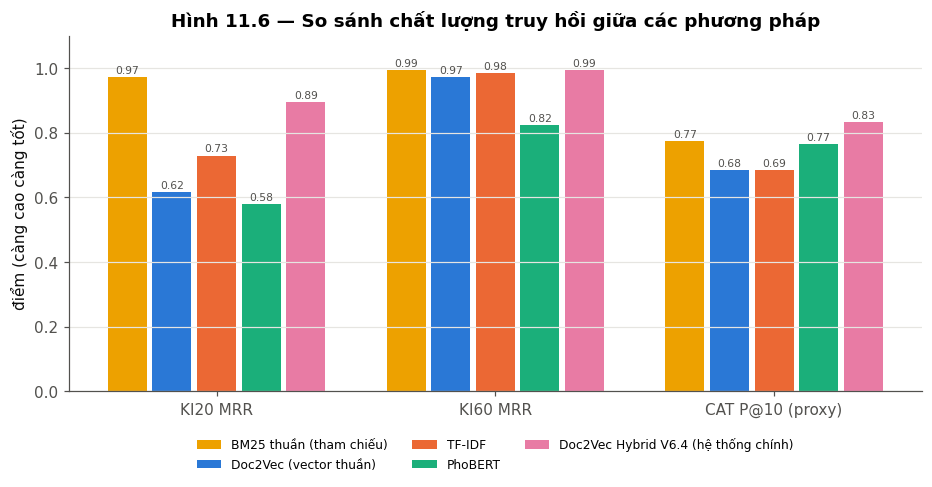

Đã lưu hình: /content/drive/MyDrive/Colab_Notebooks/Ki_2/IRS/figures/11_7_latency.png


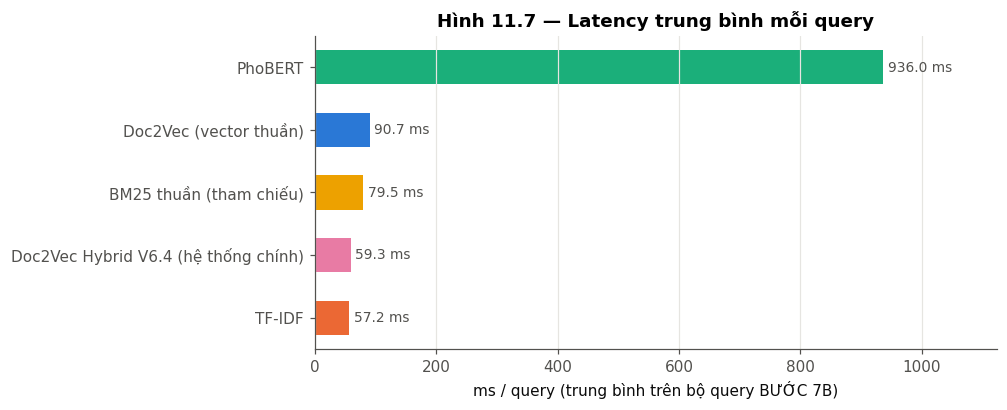

Phần cứng: x86_64 · 2 CPU threads · GPU: không dùng GPU


In [21]:
# ============================================================
# BƯỚC 11D — SO SÁNH CÁC PHƯƠNG PHÁP (cùng bộ query BƯỚC 7B)
# Hybrid V6.4 & BM25 lấy từ bảng ablation; vector methods từ BƯỚC 10B (cosine).
# ============================================================

N_EVAL_QUERIES = len(QUERY_SETS["KI20"]) + len(QUERY_SETS["KI60"]) + len(CAT_QUERIES)
COMPARE_COLS = [
    "KI20 R@1", "KI20 R@10", "KI20 MRR",
    "KI60 R@1", "KI60 R@10", "KI60 MRR",
    "CAT P@10 (proxy)",
]

_abl = df_ablation.set_index("Cấu hình")
compare_rows = []

compare_rows.append({
    "Phương pháp": "BM25 thuần (tham chiếu)",
    **_abl.loc[BM25_REFERENCE, COMPARE_COLS].to_dict(),
    "Latency TB (ms)": 1000 * _abl.loc[BM25_REFERENCE, "Thời gian (s)"] / N_EVAL_QUERIES,
})

for method in VECTOR_METHODS:
    row = df_method_eval.query("`Phương pháp` == @method and `Độ đo` == 'cosine'").iloc[0]
    compare_rows.append({
        "Phương pháp": method,
        **row[COMPARE_COLS].to_dict(),
        "Latency TB (ms)": row["Latency TB (ms)"],
    })

compare_rows.append({
    "Phương pháp": HYBRID_METHOD,
    **_abl.loc["(6) V6.4 đầy đủ", COMPARE_COLS].to_dict(),
    "Latency TB (ms)": 1000 * _abl.loc["(6) V6.4 đầy đủ", "Thời gian (s)"] / N_EVAL_QUERIES,
})

df_compare = pd.DataFrame(compare_rows).set_index("Phương pháp").astype(float)

print("Bảng 11.4 — So sánh phương pháp (độ đo cosine; latency = thời gian TB mỗi query, "
      "gồm cả preprocessing query)")
display(df_compare.round(3))

# ---------------- Hình 11.6: chất lượng truy hồi ----------------
plot_metrics = ["KI20 MRR", "KI60 MRR", "CAT P@10 (proxy)"]
methods = list(df_compare.index)
bar_w = 0.8 / len(methods)
x = np.arange(len(plot_metrics))

fig, ax = plt.subplots(figsize=(10, 4.2))
for j, method in enumerate(methods):
    values = df_compare.loc[method, plot_metrics].to_numpy()
    bars = ax.bar(x - 0.4 + bar_w * (j + 0.5), values, width=bar_w - 0.02,
                  color=METHOD_COLORS.get(method, CONTEXT_GRAY), label=method)
    ax.bar_label(bars, fmt="%.2f", fontsize=7, color=TEXT_SECONDARY, padding=1)
ax.set_xticks(x, plot_metrics)
ax.set_ylim(0, 1.1)
ax.set_ylabel("điểm (càng cao càng tốt)")
ax.grid(axis="x", visible=False)
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.1), ncol=3, fontsize=8)
ax.set_title("Hình 11.6 — So sánh chất lượng truy hồi giữa các phương pháp")
save_figure(fig, "11_6_so_sanh_phuong_phap")
plt.show()

# ---------------- Hình 11.7: latency (trục riêng, không gộp với điểm) ----------------
_lat = df_compare["Latency TB (ms)"].sort_values()
fig, ax = plt.subplots(figsize=(8, 0.5 * len(_lat) + 1.2))
bars = ax.barh(_lat.index, _lat.values, height=0.55,
               color=[METHOD_COLORS.get(m, CONTEXT_GRAY) for m in _lat.index])
ax.bar_label(bars, labels=[f"{v:,.1f} ms" for v in _lat.values], padding=3,
             color=TEXT_SECONDARY, fontsize=9)
ax.set_xlabel("ms / query (trung bình trên bộ query BƯỚC 7B)")
ax.grid(axis="y", visible=False)
ax.margins(x=0.2)
ax.set_title("Hình 11.7 — Latency trung bình mỗi query")
save_figure(fig, "11_7_latency")
plt.show()

print("Phần cứng:", hardware)

## BƯỚC 12 — Giao diện web Gradio

Chạy cell dưới, trên Colab sẽ in ra **public URL** dạng `https://xxxx.gradio.live` (`share=True`; link tạm thời, chỉ hoạt động khi runtime Colab còn chạy), mở được trên máy chiếu/điện thoại để demo trước lớp. Giao diện cũng hiển thị ngay dưới cell.

Giao diện **chỉ gọi lại** các hàm đã có: `retrieve_v6_4` (BƯỚC 6), `vector_search` (BƯỚC 9) và `correct_query` (BƯỚC 8); không có logic xếp hạng mới.

| Thành phần | Chức năng |
|---|---|
| Search bar | Nhập/copy một đoạn văn bản tiếng Việt làm truy vấn |
| Dropdown **Phương pháp** | Doc2Vec Hybrid V6.4 (hệ thống chính) / Doc2Vec (vector thuần) / TF-IDF / PhoBERT |
| Dropdown **Độ đo** | cosine / euclidean / dot — chỉ áp dụng cho phương pháp vector; V6.4 cố định cosine |
| Checkbox **Tự sửa dấu / chính tả** | Query không dấu hoặc gõ sai được sửa trước khi tìm, hiển thị “Đã hiểu truy vấn là…” |
| Nút **Search** | Tìm Top-10 bằng phương pháp đang chọn |
| Nút **So sánh các phương pháp** | Chạy mọi phương pháp trên **cùng query**, hiển thị song song + độ trùng với V6.4 |

Mỗi kết quả hiển thị: thứ hạng, tiêu đề, category, điểm; với V6.4 có thêm **giải thích điểm** — thanh đóng góp của từng thành phần trong `hybrid_score = 0.65·Doc2Vec + 0.10·Category + 0.25·DocumentMatch` (giá trị gốc, giá trị min-max, trọng số, đóng góp), token/cụm từ khớp và nguồn candidate. **Latency** được tách thành thời gian sửa dấu và thời gian truy hồi.

Các trạng thái giao diện:

| Trạng thái | Hiển thị |
|---|---|
| Initial | Search bar, nút Search, hướng dẫn nhập truy vấn và ví dụ |
| Input | Người dùng nhập/sửa truy vấn (kết quả cũ giữ nguyên cho tới khi bấm Search) |
| Validation | Query rỗng/chỉ khoảng trắng → nhắc nhập từ khoá; query chỉ gồm số/ký tự đặc biệt/stopword → nhắc nhập từ có nghĩa |
| Loading | Spinner + “Đang tìm kiếm…”, kết quả cũ bị xoá, **hai nút bị khoá** cho tới khi xong (`trigger_mode="once"`) nên không gửi trùng yêu cầu |
| Results | Tổng số kết quả, latency, danh sách tài liệu |
| Empty Results | Thông báo không tìm thấy tài liệu phù hợp (ví dụ TF-IDF khi mọi từ của query nằm ngoài từ điển) |
| Error | Thông báo tìm kiếm thất bại + nút được mở lại để thử lại |
| New Search | Mỗi lần bấm là một yêu cầu mới; vì các nút bị khoá trong lúc xử lý, kết quả của yêu cầu cũ không thể về sau và ghi đè kết quả mới |

In [22]:
# ============================================================
# BƯỚC 12 — GIAO DIỆN WEB GRADIO
# Chỉ gọi lại: correct_query (B8), retrieve_v6_4 (B6), vector_search (B9)
# ============================================================
!pip -q install gradio

import html as html_lib
import gradio as gr

UI_TOP_K = V64_TOP_K
UI_SNIPPET_CHARS = 320

MEASURE_LABELS = {
    "cosine": "Cosine similarity — càng lớn càng gần",
    "euclidean": "Euclidean distance — càng nhỏ càng gần",
    "dot": "Dot product — càng lớn càng gần",
}

HYBRID_COMPONENTS = [
    # (nhãn, cột giá trị gốc, cột min-max, trọng số, màu)
    ("Doc2Vec cosine", "doc2vec_score", "doc2vec_norm", V64_DOC2VEC_WEIGHT, SERIES_COLORS[0]),
    ("Category Coverage", "category_score", "category_norm", V64_CATEGORY_WEIGHT, SERIES_COLORS[1]),
    ("Document Match", "document_match_score", "document_norm", V64_DOCUMENT_WEIGHT, SERIES_COLORS[2]),
]

UI_CSS = """
.irs-msg {padding:14px 16px;border-radius:10px;border:1px solid var(--border-color-primary);
          background:var(--block-background-fill);color:var(--body-text-color);line-height:1.6}
.irs-msg b {color:var(--body-text-color)}
.irs-info    {border-left:5px solid #2a78d6}
.irs-warning {border-left:5px solid #eda100}
.irs-error   {border-left:5px solid #e34948}
.irs-empty   {border-left:5px solid #8a8984}
.irs-ok      {border-left:5px solid #1baf7a}
.irs-spinner {display:inline-block;width:16px;height:16px;margin-right:8px;vertical-align:-3px;
              border:3px solid var(--border-color-primary);border-top-color:#2a78d6;
              border-radius:50%;animation:irs-spin .8s linear infinite}
@keyframes irs-spin {to {transform:rotate(360deg)}}
.irs-card {padding:14px 16px;margin:12px 0;border-radius:12px;
           border:1px solid var(--border-color-primary);background:var(--block-background-fill);
           color:var(--body-text-color)}
.irs-card h3 {margin:0 0 6px 0;font-size:1.05em}
.irs-meta {font-size:.88em;color:var(--body-text-color-subdued);margin-bottom:6px}
.irs-badge {display:inline-block;padding:1px 8px;border-radius:999px;font-size:.82em;
            border:1px solid var(--border-color-primary);margin-right:6px}
.irs-score {font-variant-numeric:tabular-nums;font-weight:600}
.irs-track {display:flex;gap:2px;height:12px;width:100%;max-width:420px;border-radius:6px;
            background:var(--border-color-primary);overflow:hidden;margin:6px 0}
.irs-seg {height:100%}
.irs-legend span {display:inline-block;margin-right:12px;font-size:.85em}
.irs-dot {display:inline-block;width:10px;height:10px;border-radius:2px;margin-right:4px;vertical-align:-1px}
.irs-table {border-collapse:collapse;font-size:.85em;margin:6px 0;font-variant-numeric:tabular-nums}
.irs-table th,.irs-table td {border-bottom:1px solid var(--border-color-primary);padding:3px 10px;text-align:right}
.irs-table th:first-child,.irs-table td:first-child {text-align:left}
.irs-text {white-space:pre-wrap;line-height:1.65;text-align:justify;margin-top:6px}
.irs-grid {display:grid;grid-template-columns:repeat(auto-fit,minmax(230px,1fr));gap:12px}
.irs-col {padding:10px 12px;border-radius:10px;border:1px solid var(--border-color-primary);
          background:var(--block-background-fill);color:var(--body-text-color)}
.irs-col ol {padding-left:20px;margin:6px 0}
.irs-col li {margin:4px 0;font-size:.88em}
.irs-hit {font-weight:700}
"""


def esc(value):
    return html_lib.escape(str(value))


def message_html(kind, title, body=""):
    spinner = '<span class="irs-spinner"></span>' if kind == "loading" else ""
    css = "info" if kind == "loading" else kind
    return f'<div class="irs-msg irs-{css}">{spinner}<b>{esc(title)}</b>' + (
        f"<div>{body}</div>" if body else ""
    ) + "</div>"


INITIAL_HTML = message_html(
    "info",
    "Nhập truy vấn để bắt đầu",
    "1. Gõ hoặc dán một đoạn văn bản tiếng Việt vào ô tìm kiếm (có dấu hoặc không dấu đều được).<br>"
    "2. Chọn phương pháp (mặc định: Doc2Vec Hybrid V6.4) và độ đo.<br>"
    "3. Bấm <b>Search</b> để xem Top-10, hoặc <b>So sánh các phương pháp</b> để chạy mọi phương pháp trên cùng query."
)


def prepare_query(query, autocorrect):
    """Sửa dấu/chính tả (nếu bật). Trả (query_dùng_để_tìm, html_ghi_chú, ms)."""
    t0 = time.perf_counter()
    if not autocorrect:
        return query, "", 0.0
    fixed, changes = correct_query(query)
    ms = (time.perf_counter() - t0) * 1000
    if not changes:
        return query, "", ms
    shown = ", ".join(f"{esc(a)} → <b>{esc(b)}</b>" for a, b in changes[:12])
    more = f" … (+{len(changes) - 12})" if len(changes) > 12 else ""
    note = (f'<div class="irs-msg irs-info" style="margin-top:8px">🔤 Đã hiểu truy vấn là: '
            f'<b>{esc(fixed)}</b><br><span class="irs-meta">Đã sửa: {shown}{more}. '
            f'Bỏ chọn “Tự sửa dấu / chính tả” để tìm theo truy vấn gốc.</span></div>')
    return fixed, note, ms


def format_score(score, measure):
    return f"{score:.4f}" if measure != "euclidean" else f"{score:.4f} (khoảng cách)"


def hybrid_explanation_html(row):
    segments, legend, table_rows = [], [], []
    for label, raw_col, norm_col, weight, color in HYBRID_COMPONENTS:
        contribution = weight * float(row[norm_col])
        segments.append(
            f'<div class="irs-seg" title="{esc(label)}: {contribution:.3f}" '
            f'style="width:{100 * contribution:.1f}%;background:{color}"></div>'
        )
        legend.append(f'<span><i class="irs-dot" style="background:{color}"></i>'
                      f'{esc(label)} {contribution:.3f}</span>')
        table_rows.append(
            f"<tr><td>{esc(label)}</td><td>{float(row[raw_col]):.4f}</td>"
            f"<td>{float(row[norm_col]):.3f}</td><td>× {weight:.2f}</td>"
            f"<td><b>{contribution:.3f}</b></td></tr>"
        )
    tokens = ", ".join(row["matched_query_tokens"]) or "—"
    phrases = ", ".join(row["matched_query_phrases"]) or "—"
    return (
        f'<div class="irs-track">{"".join(segments)}</div>'
        f'<div class="irs-legend">{"".join(legend)}</div>'
        "<details><summary>Giải thích điểm</summary>"
        '<table class="irs-table"><tr><th>Thành phần</th><th>Giá trị gốc</th>'
        "<th>Min-max trong pool</th><th>Trọng số</th><th>Đóng góp</th></tr>"
        + "".join(table_rows)
        + f'<tr><td><b>hybrid_score</b></td><td></td><td></td><td></td>'
          f'<td><b>{float(row["hybrid_score"]):.3f}</b></td></tr></table>'
        f'<div class="irs-meta">Token khớp: {esc(tokens)}<br>Cụm từ khớp: {esc(phrases)}<br>'
        f'Nguồn candidate: {esc(row["candidate_source"])} · hạng theo cosine trong pool: '
        f'{int(row["doc2vec_rank"])}<br>hybrid_score là điểm tương đối trong query này '
        f"(min-max theo candidate pool), không phải xác suất.</div></details>"
    )


def result_card_html(row, method, measure):
    text = str(row["text_raw"])
    snippet = text[:UI_SNIPPET_CHARS] + ("…" if len(text) > UI_SNIPPET_CHARS else "")
    if method == HYBRID_METHOD:
        score_line = f'hybrid_score <span class="irs-score">{float(row["score"]):.4f}</span>'
        explanation = hybrid_explanation_html(row)
    else:
        score_line = (f'{esc(measure)} <span class="irs-score">'
                      f'{esc(format_score(float(row["score"]), measure))}</span>')
        explanation = ""
    return (
        '<div class="irs-card">'
        f'<h3>#{int(row["rank"])} — {esc(row["title"][:160])}</h3>'
        f'<div class="irs-meta"><span class="irs-badge">{esc(row["category"])}</span>'
        f'{esc(row["doc_id"])} · {score_line}</div>'
        f"{explanation}"
        f'<div class="irs-text">{esc(snippet)}</div>'
        f'<details><summary>Xem toàn văn</summary><div class="irs-text">{esc(text)}</div></details>'
        "</div>"
    )


def results_header_html(n, method, measure, correct_ms, search_ms):
    measure_text = "cosine (cố định)" if method == HYBRID_METHOD else MEASURE_LABELS[measure]
    return message_html(
        "ok",
        f"Tìm thấy {n} kết quả",
        f"Phương pháp: <b>{esc(method)}</b> · Độ đo: {esc(measure_text)}<br>"
        f"⏱ Latency: <b>{correct_ms + search_ms:,.0f} ms</b> "
        f"(sửa dấu/chính tả {correct_ms:,.0f} ms + truy hồi {search_ms:,.0f} ms)"
    )


def is_blank(query):
    return query is None or not str(query).strip()


BUTTONS_LOCKED = (gr.update(interactive=False), gr.update(interactive=False))
BUTTONS_FREE = (gr.update(interactive=True), gr.update(interactive=True))

VALIDATION_EMPTY = message_html(
    "warning", "Vui lòng nhập từ khoá hoặc đoạn văn bản cần tìm.",
    "Ô tìm kiếm đang trống hoặc chỉ có khoảng trắng."
)


def validation_no_token(note=""):
    return message_html(
        "warning", "Truy vấn không có từ khoá hợp lệ.",
        "Sau tiền xử lý, truy vấn chỉ còn số, ký tự đặc biệt hoặc stopword. "
        "Hãy nhập từ khoá có nghĩa (ví dụ: <i>giá vàng tăng</i>)."
    ) + note


def search_handler(query, method, measure, autocorrect):
    """Generator: yield (status, results, search_btn, compare_btn)."""
    if is_blank(query):
        yield (VALIDATION_EMPTY, "", *BUTTONS_FREE)
        return

    yield (message_html("loading", "Đang tìm kiếm…", f"Phương pháp: {esc(method)}"),
           "", *BUTTONS_LOCKED)

    try:
        search_query, note, correct_ms = prepare_query(query.strip(), autocorrect)
        t0 = time.perf_counter()
        results = run_search(method, search_query, measure=measure, top_k=UI_TOP_K)
        search_ms = (time.perf_counter() - t0) * 1000
    except ValueError as e:
        if "token" in str(e) or "trống" in str(e):
            yield (validation_no_token(), "", *BUTTONS_FREE)
        else:
            yield (message_html("error", "Tìm kiếm thất bại. Hãy bấm Search để thử lại.",
                                f"Chi tiết: {esc(e)}"), "", *BUTTONS_FREE)
        return
    except Exception as e:
        yield (message_html("error", "Tìm kiếm thất bại. Hãy bấm Search để thử lại.",
                            f"Chi tiết: {esc(type(e).__name__)}: {esc(e)}"), "", *BUTTONS_FREE)
        return

    if results.empty:
        yield (message_html("empty", "Không tìm thấy tài liệu phù hợp.",
                            "Thử từ khoá khác, bật tự sửa dấu/chính tả, hoặc đổi phương pháp.") + note,
               "", *BUTTONS_FREE)
        return

    header = results_header_html(len(results), method, measure, correct_ms, search_ms)
    cards = "".join(result_card_html(row, method, measure) for _, row in results.iterrows())
    yield (header + note, cards, *BUTTONS_FREE)


def compare_handler(query, measure, autocorrect):
    """Chạy mọi phương pháp trên cùng query; hiển thị song song."""
    if is_blank(query):
        yield (VALIDATION_EMPTY, "", *BUTTONS_FREE)
        return

    yield (message_html("loading", "Đang chạy tất cả phương pháp…",
                        ", ".join(esc(m) for m in METHOD_CHOICES)), "", *BUTTONS_LOCKED)

    try:
        search_query, note, correct_ms = prepare_query(query.strip(), autocorrect)
        runs = {}
        for method in METHOD_CHOICES:
            t0 = time.perf_counter()
            runs[method] = run_search(method, search_query, measure=measure, top_k=UI_TOP_K)
            runs[method].attrs["ms"] = (time.perf_counter() - t0) * 1000
    except ValueError:
        yield (validation_no_token(), "", *BUTTONS_FREE)
        return
    except Exception as e:
        yield (message_html("error", "So sánh thất bại. Hãy bấm lại để thử lại.",
                            f"Chi tiết: {esc(type(e).__name__)}: {esc(e)}"), "", *BUTTONS_FREE)
        return

    hybrid_ids = set(runs[HYBRID_METHOD]["doc_id"])
    columns = []
    for method, results in runs.items():
        overlap = len(set(results["doc_id"]) & hybrid_ids)
        items = "".join(
            f'<li class="{"irs-hit" if row["doc_id"] in hybrid_ids and method != HYBRID_METHOD else ""}">'
            f'{esc(row["title"][:90])} <span class="irs-badge">{esc(row["category"])}</span></li>'
            for _, row in results.iterrows()
        ) or "<li>Không có kết quả</li>"
        measure_text = "cosine (cố định)" if method == HYBRID_METHOD else measure
        columns.append(
            f'<div class="irs-col"><b>{esc(method)}</b>'
            f'<div class="irs-meta">độ đo: {esc(measure_text)} · ⏱ {results.attrs["ms"]:,.0f} ms'
            + ("" if method == HYBRID_METHOD else f" · trùng V6.4: {overlap}/{len(hybrid_ids)}")
            + f"</div><ol>{items}</ol></div>"
        )

    header = message_html(
        "ok", f"So sánh {len(runs)} phương pháp trên cùng truy vấn",
        f"Chữ <b>đậm</b> = tài liệu cũng nằm trong Top-{UI_TOP_K} của V6.4. "
        f"Sửa dấu/chính tả: {correct_ms:,.0f} ms."
    )
    yield (header + note, f'<div class="irs-grid">{"".join(columns)}</div>', *BUTTONS_FREE)


def on_method_change(method):
    if method == HYBRID_METHOD:
        return gr.update(value="cosine", interactive=False,
                         info="V6.4 luôn dùng cosine (thiết kế BƯỚC 6).")
    return gr.update(interactive=True, info="Áp dụng cho phương pháp vector đang chọn.")


UI_EXAMPLES = [
    ["tai nan giao thong"],
    ["Tai nạm giao thông ở Hà Nội"],
    ["Giá vàng tăng mạnh, ngân hàng nhà nước điều chỉnh lãi suất"],
    [test_query.strip()],
]

# Gradio 6 chuyển theme/css từ gr.Blocks() sang launch(); hỗ trợ cả bản 5 và 6
GRADIO_MAJOR = int(gr.__version__.split(".")[0])
UI_STYLE = dict(css=UI_CSS, theme=gr.themes.Soft())
BLOCKS_STYLE = UI_STYLE if GRADIO_MAJOR < 6 else {}
LAUNCH_STYLE = UI_STYLE if GRADIO_MAJOR >= 6 else {}

with gr.Blocks(title="Vietnamese Document Retrieval", **BLOCKS_STYLE) as demo:
    gr.Markdown(
        "# 🔎 Hệ truy hồi văn bản tiếng Việt\n"
        f"Doc2Vec Hybrid V6.4 · so sánh TF-IDF / PhoBERT · {len(df_docs):,} bài báo, "
        f"{df_docs[CATEGORY_COL].nunique()} category"
    )

    query_box = gr.Textbox(
        label="Truy vấn",
        placeholder="Nhập hoặc dán đoạn văn bản cần tìm (có dấu hoặc không dấu)…",
        lines=4,
        max_lines=12,
    )

    with gr.Row():
        method_dd = gr.Dropdown(METHOD_CHOICES, value=HYBRID_METHOD, label="Phương pháp")
        measure_dd = gr.Dropdown(
            SIMILARITY_MEASURES, value="cosine", label="Độ đo", interactive=False,
            info="V6.4 luôn dùng cosine (thiết kế BƯỚC 6)."
        )
        autocorrect_cb = gr.Checkbox(value=True, label="Tự sửa dấu / chính tả")

    with gr.Row():
        search_btn = gr.Button("🔍 Search", variant="primary")
        compare_btn = gr.Button("⚖️ So sánh các phương pháp")

    gr.Examples(UI_EXAMPLES, inputs=[query_box], label="Ví dụ truy vấn")

    status_html = gr.HTML(INITIAL_HTML)
    results_html = gr.HTML("")

    method_dd.change(on_method_change, inputs=method_dd, outputs=measure_dd)

    search_btn.click(
        search_handler,
        inputs=[query_box, method_dd, measure_dd, autocorrect_cb],
        outputs=[status_html, results_html, search_btn, compare_btn],
        trigger_mode="once",
        show_progress="minimal",
    )
    compare_btn.click(
        compare_handler,
        inputs=[query_box, measure_dd, autocorrect_cb],
        outputs=[status_html, results_html, search_btn, compare_btn],
        trigger_mode="once",
        show_progress="minimal",
    )

demo.queue(default_concurrency_limit=2)
demo.launch(share=IN_COLAB, show_error=True, **LAUNCH_STYLE)

Colab notebook detected. To show errors in colab notebook, set debug=True in launch()
* Running on public URL: https://713971cba19cb691e0.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)
